# Edge AI: Parkplatzbelegung

Ausführbare Dokumentation der Implementierung. Die gespeicherten Ausgaben stammen vom ursprünglichen Projektlauf auf einem Apple-Silicon-Mac. Für eine Reproduktion die Zellen in Reihenfolge ausführen; Voraussetzungen und Dateien stehen in README.md.


In [2]:
from pathlib import Path
import sys
import platform
import torch
import onnxruntime as ort

print("Arbeitsordner:", Path.cwd())
print("Python-Umgebung:", sys.executable)
print("Architektur:", platform.machine())
print("Apple-GPU verfügbar:", torch.backends.mps.is_available())
print("ONNX Runtime:", ort.__version__)

Arbeitsordner: <PROJEKTORDNER>
Python-Umgebung: <CONDA-UMGEBUNG>/bin/python
Architektur: arm64
Apple-GPU verfügbar: True
ONNX Runtime: 1.30.0


In [4]:
%pip install kagglehub

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached certifi-2026.7.22-py3-none-any.whl (136 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [kagglehub]━ 7/9 [kagglesdk]
Note: you may need to restart the kernel to use updated packages.


## Datensatz

PKLot Version 1 wird über KaggleHub bezogen; Rohbilder und COCO-Annotationen liegen im KaggleHub-Cache. Die ursprüngliche Train/Valid/Test-Zuordnung wird geprüft, anschließend erfolgt ein eigener Tagessplit.


In [6]:
from pathlib import Path
import kagglehub

datenordner = Path(
    kagglehub.dataset_download("ammarnassanalhajali/pklot-dataset/versions/1")
)

print("Datensatz liegt hier:", datenordner)
print("Inhalt:")
for eintrag in sorted(datenordner.iterdir())[:20]:
    print("📁" if eintrag.is_dir() else "📄", eintrag.name)

<CONDA-UMGEBUNG>/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|███████████████████████████████████████| 843M/843M [02:51<00:00, 5.16MB/s]

Extracting files...


Datensatz liegt hier: ~/.cache/kagglehub/datasets/ammarnassanalhajali/pklot-dataset/versions/1
Inhalt:
📄 README.dataset.txt
📄 README.roboflow.txt
📁 test
📁 train
📁 valid


In [4]:
from pathlib import Path

datenordner = Path(kagglehub.dataset_download("ammarnassanalhajali/pklot-dataset/versions/1"))

print("Datensatz vorhanden:", datenordner.exists())

Datensatz vorhanden: True


In [6]:
from pathlib import Path

for name in ["README.dataset.txt", "README.roboflow.txt"]:
    datei = datenordner / name
    print(f"\n--- {name} ---")
    print(datei.read_text(errors="replace")[:1200])

for split in ["train", "valid", "test"]:
    ordner = datenordner / split
    print(f"\n--- {split} ---")
    print("Unterordner:", [p.name for p in ordner.iterdir() if p.is_dir()])

    for typ in ["images", "labels"]:
        pfad = ordner / typ
        if pfad.exists():
            dateien = sorted(p for p in pfad.iterdir() if p.is_file())
            print(f"{typ}: {len(dateien)} Dateien")
            if dateien:
                print("Beispiel:", dateien[0].name)

labels = sorted((datenordner / "train" / "labels").glob("*.txt"))
if labels:
    print("\n--- Beispiel einer Beschriftung ---")
    print(labels[0].name)
    print("\n".join(labels[0].read_text().splitlines()[:5]))


--- README.dataset.txt ---
# PKLot > 640
https://public.roboflow.ai/object-detection/pklot

Provided by [Universidade Federal do Parana](https://web.inf.ufpr.br/vri/databases/parking-lot-database/)
License: CC BY 4.0

![Parking Lot Dataset](https://i.imgur.com/Hnda0gD.png)

The PKLot dataset contains 12,416 images of parking lots extracted from surveilance camera frames. There are images on sunny, cloudy, and rainy days and the parking spaces are labeled as occupied or empty. We have converted the original annotations to a variety of standard object detection formats by enclosing a bounding box around the original dataset's rotated rectangle annotations.

## Using this Dataset
The PKLot database is licensed under a Creative Commons Attribution 4.0 License and may be used provided you acknowledge the source by citing the [PKLot paper](http://www.inf.ufpr.br/lesoliveira/download/ESWA2015.pdf) in publications about your research:

```
Almeida, P., Oliveira, L. S., Silva Jr, E., Britto Jr

In [8]:
import json
from collections import Counter

for split in ["train", "valid", "test"]:
    ordner = datenordner / split
    dateien = list(ordner.iterdir())
    bilder = sorted(
        p for p in dateien
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    json_dateien = sorted(p for p in dateien if p.suffix.lower() == ".json")

    print(f"\n--- {split} ---")
    print("Dateitypen:", dict(Counter(p.suffix.lower() for p in dateien)))
    print("Beispielbilder:", [p.name for p in bilder[:3]])
    print("Beschriftungsdateien:", [p.name for p in json_dateien])

    if json_dateien:
        daten = json.loads(json_dateien[0].read_text())
        print("Klassen:", daten.get("categories"))
        print("Anzahl Bilder:", len(daten.get("images", [])))
        print("Anzahl Stellplatz-Markierungen:", len(daten.get("annotations", [])))
        print("Erster Bildeintrag:", daten["images"][0])
        erste_markierung = daten["annotations"][0]
        print("Erste Markierung:", {
            key: erste_markierung.get(key)
            for key in ["image_id", "category_id", "bbox"]
        })


--- train ---
Dateitypen: {'.jpg': 8691, '.json': 1}
Beispielbilder: ['2012-09-11_15_16_58_jpg.rf.61d961a86c9a16694403dfcb72cd450c.jpg', '2012-09-11_15_27_08_jpg.rf.0f38b15658ce17d10ce40a992adae5ba.jpg', '2012-09-11_15_29_29_jpg.rf.3819d0bdff07fb09e87e5cc7d51dc662.jpg']
Beschriftungsdateien: ['_annotations.coco.json']
Klassen: [{'id': 0, 'name': 'spaces', 'supercategory': 'none'}, {'id': 1, 'name': 'space-empty', 'supercategory': 'spaces'}, {'id': 2, 'name': 'space-occupied', 'supercategory': 'spaces'}]
Anzahl Bilder: 8691
Anzahl Stellplatz-Markierungen: 497856
Erster Bildeintrag: {'id': 0, 'license': 1, 'file_name': '2013-04-10_12_00_06_jpg.rf.bef78f7879666a6d8997ce513fd8d124.jpg', 'height': 640, 'width': 640, 'date_captured': '2021-01-05T21:55:11+00:00'}
Erste Markierung: {'image_id': 0, 'category_id': 2, 'bbox': [304, 468, 83.5, 114]}

--- valid ---
Dateitypen: {'.jpg': 2483, '.json': 1}
Beispielbilder: ['2012-09-11_15_36_32_jpg.rf.b2b1767cafabff6378468d0d71c1ecd2.jpg', '2012-09-11

In [10]:
import json
from collections import Counter

tage_pro_split = {}

for split in ["train", "valid", "test"]:
    pfad = datenordner / split / "_annotations.coco.json"
    coco = json.loads(pfad.read_text())

    tage = Counter(bild["file_name"][:10] for bild in coco["images"])
    klassen = Counter(a["category_id"] for a in coco["annotations"])
    tage_pro_split[split] = set(tage)

    print(f"\n{split}: {len(tage)} Aufnahmetage")
    print("Häufigste Tage:", tage.most_common(3))
    print("Stellplätze je Klasse:", dict(sorted(klassen.items())))

for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    gemeinsam = tage_pro_split[a] & tage_pro_split[b]
    print(f"{a} und {b}: {len(gemeinsam)} gemeinsame Tage")

print("Tage insgesamt:", len(set.union(*tage_pro_split.values())))


train: 100 Aufnahmetage
Häufigste Tage: [('2012-10-11', 127), ('2012-11-10', 126), ('2013-01-20', 124)]
Stellplätze je Klasse: {1: 265908, 2: 231948}

valid: 99 Aufnahmetage
Häufigste Tage: [('2013-03-05', 40), ('2012-12-25', 38), ('2013-01-17', 38)]
Stellplätze je Klasse: {1: 73629, 2: 69687}

test: 96 Aufnahmetage
Häufigste Tage: [('2012-10-11', 25), ('2013-01-21', 23), ('2013-03-16', 22)]
Stellplätze je Klasse: {1: 36584, 2: 34100}
train und valid: 99 gemeinsame Tage
train und test: 96 gemeinsame Tage
valid und test: 96 gemeinsame Tage
Tage insgesamt: 100


## Tagessplit

100 Aufnahmetage werden mit Seed 42 neu in 70 Trainingstage, 15 Validierungstage und 15 Testtage aufgeteilt. Die Zuordnung wird in `split_nach_tagen.json` gespeichert.


In [12]:
import json
import random
from collections import Counter
from pathlib import Path

# Alle ursprünglichen Aufnahmetage sammeln
alle_tage = set()

for ordnername in ["train", "valid", "test"]:
    datei = datenordner / ordnername / "_annotations.coco.json"
    with datei.open(encoding="utf-8") as f:
        coco = json.load(f)

    alle_tage.update(
        bild["file_name"][:10] for bild in coco["images"]
    )

# Reproduzierbar mischen und ganze Tage zuordnen
tage = sorted(alle_tage)
random.Random(42).shuffle(tage)

tagessplit = {}
for nummer, tag in enumerate(tage):
    if nummer < 70:
        tagessplit[tag] = "train"
    elif nummer < 85:
        tagessplit[tag] = "valid"
    else:
        tagessplit[tag] = "test"

# Zuordnung im Projektordner sichern
ausgabe = Path.cwd() / "split_nach_tagen.json"
ausgabe.write_text(
    json.dumps({"seed": 42, "tagessplit": tagessplit}, indent=2),
    encoding="utf-8"
)

print("Aufnahmetage insgesamt:", len(tage))
print("Aufteilung:", dict(Counter(tagessplit.values())))
print("Gespeichert unter:", ausgabe)

Aufnahmetage insgesamt: 100
Aufteilung: {'train': 70, 'valid': 15, 'test': 15}
Gespeichert unter: <PROJEKTORDNER>/split_nach_tagen.json


In [14]:
import json
from collections import defaultdict, Counter
from pathlib import Path

datei = Path.cwd() / "split_nach_tagen.json"
tagessplit = json.loads(datei.read_text(encoding="utf-8"))["tagessplit"]

statistik = defaultdict(Counter)

for original_split in ["train", "valid", "test"]:
    pfad = datenordner / original_split / "_annotations.coco.json"
    with pfad.open(encoding="utf-8") as f:
        coco = json.load(f)

    bildinfo = {}
    for bild in coco["images"]:
        neuer_split = tagessplit[bild["file_name"][:10]]
        bildinfo[bild["id"]] = (
            neuer_split, bild["width"], bild["height"]
        )
        statistik[neuer_split]["bilder"] += 1

    for markierung in coco["annotations"]:
        neuer_split, breite, hoehe = bildinfo[markierung["image_id"]]
        klasse = markierung["category_id"]
        x, y, w, h = markierung["bbox"]

        statistik[neuer_split][f"klasse_{klasse}"] += 1

        if w < 20 or h < 20:
            statistik[neuer_split]["kleiner_als_20px"] += 1

        if w <= 0 or h <= 0 or x < 0 or y < 0 or x + w > breite or y + h > hoehe:
            statistik[neuer_split]["ungueltige_box"] += 1

for split in ["train", "valid", "test"]:
    s = statistik[split]
    gesamt = s["klasse_1"] + s["klasse_2"]
    print(f"\n{split}:")
    print("  Ganze Bilder:", s["bilder"])
    print("  Frei:", s["klasse_1"])
    print("  Belegt:", s["klasse_2"])
    print("  Anteil belegt:", round(100 * s["klasse_2"] / gesamt, 1), "%")
    print("  Sehr kleine Ausschnitte:", s["kleiner_als_20px"])
    print("  Ungültige Markierungen:", s["ungueltige_box"])


train:
  Ganze Bilder: 8741
  Frei: 251879
  Belegt: 239537
  Anteil belegt: 48.7 %
  Sehr kleine Ausschnitte: 64722
  Ungültige Markierungen: 0

valid:
  Ganze Bilder: 1913
  Frei: 46326
  Belegt: 51098
  Anteil belegt: 52.4 %
  Sehr kleine Ausschnitte: 10248
  Ungültige Markierungen: 0

test:
  Ganze Bilder: 1762
  Frei: 77916
  Belegt: 45100
  Anteil belegt: 36.7 %
  Sehr kleine Ausschnitte: 18963
  Ungültige Markierungen: 0


Matplotlib is building the font cache; this may take a moment.


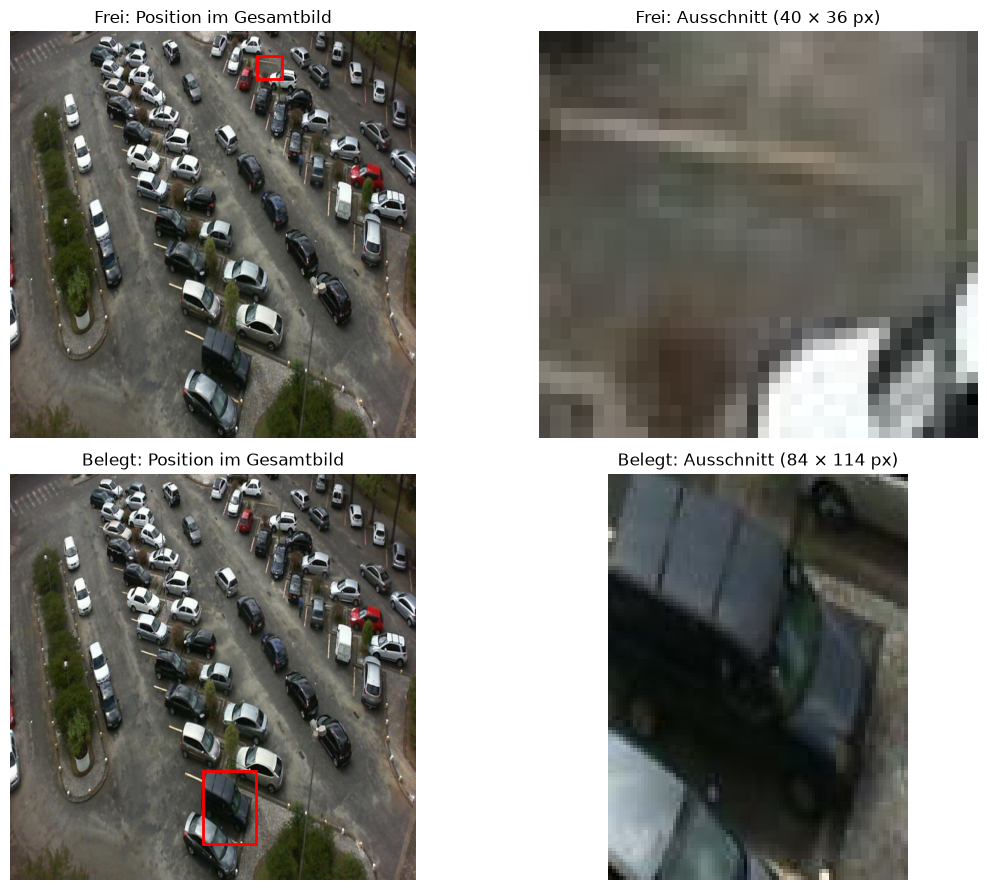

In [16]:
import json
import math
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

pfad = datenordner / "train" / "_annotations.coco.json"
with pfad.open(encoding="utf-8") as f:
    coco = json.load(f)

bilder = {bild["id"]: bild for bild in coco["images"]}
beispiele = {}

for markierung in coco["annotations"]:
    klasse = markierung["category_id"]
    x, y, w, h = markierung["bbox"]

    if klasse in (1, 2) and klasse not in beispiele and w >= 20 and h >= 20:
        beispiele[klasse] = markierung
    if len(beispiele) == 2:
        break

fig, achsen = plt.subplots(2, 2, figsize=(12, 9))

for zeile, klasse in enumerate((1, 2)):
    markierung = beispiele[klasse]
    bildname = bilder[markierung["image_id"]]["file_name"]
    bild = Image.open(datenordner / "train" / bildname).convert("RGB")
    x, y, w, h = markierung["bbox"]

    ausschnitt = bild.crop((
        math.floor(x), math.floor(y),
        math.ceil(x + w), math.ceil(y + h)
    ))

    bezeichnung = "Frei" if klasse == 1 else "Belegt"
    achsen[zeile, 0].imshow(bild)
    achsen[zeile, 0].add_patch(
        Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=2)
    )
    achsen[zeile, 0].set_title(f"{bezeichnung}: Position im Gesamtbild")
    achsen[zeile, 1].imshow(ausschnitt)
    achsen[zeile, 1].set_title(f"{bezeichnung}: Ausschnitt ({w:.0f} × {h:.0f} px)")

    for achse in achsen[zeile]:
        achse.axis("off")

plt.tight_layout()
plt.show()

In [18]:
import json
from collections import Counter, defaultdict

grenzen = (40, 48, 64)
anzahlen = {grenze: defaultdict(Counter) for grenze in grenzen}

for original_split in ["train", "valid", "test"]:
    pfad = datenordner / original_split / "_annotations.coco.json"
    with pfad.open(encoding="utf-8") as f:
        coco = json.load(f)

    gruppe_pro_bild = {
        bild["id"]: tagessplit[bild["file_name"][:10]]
        for bild in coco["images"]
    }

    for markierung in coco["annotations"]:
        klasse = markierung["category_id"]
        if klasse not in (1, 2):
            continue

        _, _, breite, hoehe = markierung["bbox"]
        gruppe = gruppe_pro_bild[markierung["image_id"]]

        for grenze in grenzen:
            if breite >= grenze and hoehe >= grenze:
                anzahlen[grenze][gruppe][klasse] += 1

for grenze in grenzen:
    print(f"\nMindestens {grenze} × {grenze} Pixel:")
    for gruppe in ["train", "valid", "test"]:
        print(
            f"  {gruppe}: "
            f"{anzahlen[grenze][gruppe][1]} frei, "
            f"{anzahlen[grenze][gruppe][2]} belegt"
        )


Mindestens 40 × 40 Pixel:
  train: 55540 frei, 65964 belegt
  valid: 14855 frei, 18765 belegt
  test: 8363 frei, 14045 belegt

Mindestens 48 × 48 Pixel:
  train: 35775 frei, 46159 belegt
  valid: 9939 frei, 12606 belegt
  test: 5719 frei, 9643 belegt

Mindestens 64 × 64 Pixel:
  train: 10629 frei, 15809 belegt
  valid: 2749 frei, 3612 belegt
  test: 1636 frei, 2659 belegt


## Vorversuch zur Stichprobenwahl

Die folgende Zelle mit 48-Pixel-Grenze erzeugt eine **vorläufige** `stichprobe.csv`. Die endgültige Auswahl steht weiter unten und überschreibt diese Datei. Für die berichteten Ergebnisse gilt ausschließlich die endgültige Auswahl.


In [20]:
import json
import random
from pathlib import Path
import pandas as pd

tagessplit = json.loads(
    (Path.cwd() / "split_nach_tagen.json").read_text(encoding="utf-8")
)["tagessplit"]

kandidaten = {
    "train": {1: [], 2: []},
    "valid": [],
    "test": [],
}

for original_split in ["train", "valid", "test"]:
    pfad = datenordner / original_split / "_annotations.coco.json"
    with pfad.open(encoding="utf-8") as f:
        coco = json.load(f)

    bilder = {bild["id"]: bild for bild in coco["images"]}

    for markierung in coco["annotations"]:
        klasse = markierung["category_id"]
        if klasse not in (1, 2):
            continue

        bildname = bilder[markierung["image_id"]]["file_name"]
        datum = bildname[:10]
        gruppe = tagessplit[datum]
        x, y, breite, hoehe = markierung["bbox"]

        # Nur beim Training sehr kleine Ausschnitte ausschließen
        if gruppe == "train" and (breite < 48 or hoehe < 48):
            continue

        zeile = {
            "gruppe": gruppe,
            "original_split": original_split,
            "bildname": bildname,
            "datum": datum,
            "klasse": "frei" if klasse == 1 else "belegt",
            "x": x,
            "y": y,
            "breite": breite,
            "hoehe": hoehe,
        }

        if gruppe == "train":
            kandidaten["train"][klasse].append(zeile)
        else:
            kandidaten[gruppe].append(zeile)

zufall = random.Random(42)

auswahl = (
    zufall.sample(kandidaten["train"][1], 6000)
    + zufall.sample(kandidaten["train"][2], 6000)
    + zufall.sample(kandidaten["valid"], 2000)
    + zufall.sample(kandidaten["test"], 3000)
)

stichprobe = pd.DataFrame(auswahl)
csv_pfad = Path.cwd() / "stichprobe.csv"
stichprobe.to_csv(csv_pfad, index=False)

print("Gespeichert:", csv_pfad)
print("\nBeispiele je Gruppe und Klasse:")
print(pd.crosstab(stichprobe["gruppe"], stichprobe["klasse"]))
print("\nVerschiedene Aufnahmetage:")
print(stichprobe.groupby("gruppe")["datum"].nunique())

Gespeichert: <PROJEKTORDNER>/stichprobe.csv

Beispiele je Gruppe und Klasse:
klasse  belegt  frei
gruppe              
test      1150  1850
train     6000  6000
valid     1058   942

Verschiedene Aufnahmetage:
gruppe
test     15
train    45
valid    14
Name: datum, dtype: int64


In [22]:
import json
from collections import Counter

grenzen = (16, 20, 24, 32, 40, 48)
tage_mit_bildern = {g: set() for g in grenzen}
tage_je_klasse = {g: {1: set(), 2: set()} for g in grenzen}
anzahl_je_klasse = {g: Counter() for g in grenzen}

for original_split in ["train", "valid", "test"]:
    pfad = datenordner / original_split / "_annotations.coco.json"
    with pfad.open(encoding="utf-8") as f:
        coco = json.load(f)

    datum_pro_bild = {
        bild["id"]: bild["file_name"][:10]
        for bild in coco["images"]
    }

    for markierung in coco["annotations"]:
        klasse = markierung["category_id"]
        if klasse not in (1, 2):
            continue

        datum = datum_pro_bild[markierung["image_id"]]
        if tagessplit[datum] != "train":
            continue

        _, _, breite, hoehe = markierung["bbox"]
        for grenze in grenzen:
            if breite >= grenze and hoehe >= grenze:
                tage_mit_bildern[grenze].add(datum)
                tage_je_klasse[grenze][klasse].add(datum)
                anzahl_je_klasse[grenze][klasse] += 1

for grenze in grenzen:
    print(
        f"{grenze:2d} px: "
        f"{len(tage_mit_bildern[grenze])}/70 Tage, "
        f"frei an {len(tage_je_klasse[grenze][1])} Tagen, "
        f"belegt an {len(tage_je_klasse[grenze][2])} Tagen"
    )

16 px: 69/70 Tage, frei an 69 Tagen, belegt an 64 Tagen
20 px: 69/70 Tage, frei an 69 Tagen, belegt an 63 Tagen
24 px: 69/70 Tage, frei an 69 Tagen, belegt an 63 Tagen
32 px: 69/70 Tage, frei an 69 Tagen, belegt an 58 Tagen
40 px: 45/70 Tage, frei an 45 Tagen, belegt an 40 Tagen
48 px: 45/70 Tage, frei an 45 Tagen, belegt an 39 Tagen


## Endgültige Stichprobe und Ausschnitte

Die Auswahl mit Mindestkante 24 Pixel für Training und Tagessabdeckung erzeugt die finale `stichprobe.csv` mit 12.000 Trainings-, 2.000 Validierungs- und 3.000 Testausschnitten.


In [24]:
import json
import random
from collections import defaultdict
from pathlib import Path
import pandas as pd

tagessplit = json.loads(
    (Path.cwd() / "split_nach_tagen.json").read_text(encoding="utf-8")
)["tagessplit"]

gruppen = ("train", "valid", "test")
pool = {
    gruppe: {1: defaultdict(list), 2: defaultdict(list)}
    for gruppe in gruppen
}

for original_split in gruppen:
    pfad = datenordner / original_split / "_annotations.coco.json"
    with pfad.open(encoding="utf-8") as f:
        coco = json.load(f)

    bilder = {bild["id"]: bild for bild in coco["images"]}

    for markierung in coco["annotations"]:
        klasse = markierung["category_id"]
        if klasse not in (1, 2):
            continue

        bildname = bilder[markierung["image_id"]]["file_name"]
        datum = bildname[:10]
        gruppe = tagessplit[datum]
        x, y, breite, hoehe = markierung["bbox"]

        if gruppe == "train" and (breite < 24 or hoehe < 24):
            continue

        pool[gruppe][klasse][datum].append({
            "gruppe": gruppe,
            "original_split": original_split,
            "bildname": bildname,
            "datum": datum,
            "klasse": "frei" if klasse == 1 else "belegt",
            "x": x,
            "y": y,
            "breite": breite,
            "hoehe": hoehe,
            "markierung_id": f"{original_split}:{markierung['id']}",
        })

zufall = random.Random(42)

def auswahl_mit_tagesabdeckung(tagesgruppen, anzahl):
    # Zuerst ein Beispiel aus jedem verfügbaren Tag
    reserviert = [
        zufall.choice(tagesgruppen[tag])
        for tag in sorted(tagesgruppen)
        if tagesgruppen[tag]
    ]
    reservierte_ids = {zeile["markierung_id"] for zeile in reserviert}

    uebrig = [
        zeile
        for tag in sorted(tagesgruppen)
        for zeile in tagesgruppen[tag]
        if zeile["markierung_id"] not in reservierte_ids
    ]
    return reserviert + zufall.sample(uebrig, anzahl - len(reserviert))

def beide_klassen(gruppe):
    zusammen = defaultdict(list)
    for klasse in (1, 2):
        for tag, zeilen in pool[gruppe][klasse].items():
            zusammen[tag].extend(zeilen)
    return zusammen

auswahl = (
    auswahl_mit_tagesabdeckung(pool["train"][1], 6000)
    + auswahl_mit_tagesabdeckung(pool["train"][2], 6000)
    + auswahl_mit_tagesabdeckung(beide_klassen("valid"), 2000)
    + auswahl_mit_tagesabdeckung(beide_klassen("test"), 3000)
)

stichprobe = pd.DataFrame(auswahl)
stichprobe = stichprobe.sample(frac=1, random_state=42).reset_index(drop=True)
stichprobe.to_csv(Path.cwd() / "stichprobe.csv", index=False)

print(pd.crosstab(stichprobe["gruppe"], stichprobe["klasse"]))
print("\nAbgedeckte Tage:")
print(stichprobe.groupby("gruppe")["datum"].nunique())

train_tage = {tag for tag, gruppe in tagessplit.items() if gruppe == "train"}
vorhandene_tage = set(stichprobe.loc[stichprobe["gruppe"] == "train", "datum"])
print("\nTrainingstage ohne geeigneten Ausschnitt:", sorted(train_tage - vorhandene_tage))

klasse  belegt  frei
gruppe              
test      1071  1929
train     6000  6000
valid     1042   958

Abgedeckte Tage:
gruppe
test     15
train    69
valid    14
Name: datum, dtype: int64

Trainingstage ohne geeigneten Ausschnitt: ['2012-12-28']


Validierungstag ohne beschriftetes Beispiel: ['2012-12-29']


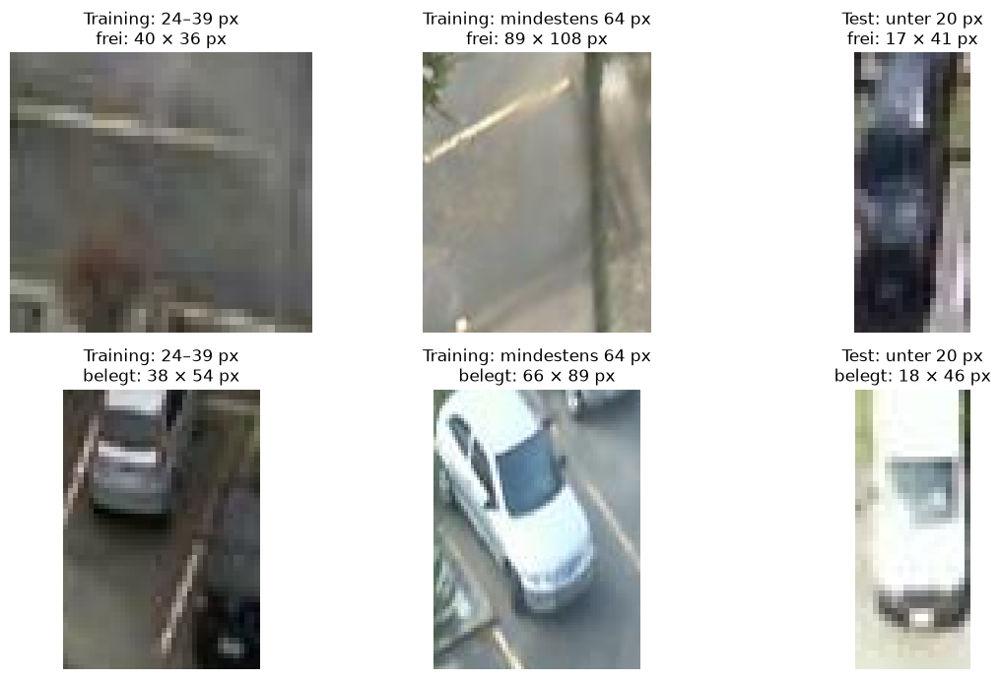

In [26]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

stichprobe = pd.read_csv(Path.cwd() / "stichprobe.csv")
stichprobe["kleinste_kante"] = stichprobe[["breite", "hoehe"]].min(axis=1)

erwartete_valid_tage = {
    tag for tag, gruppe in tagessplit.items() if gruppe == "valid"
}
vorhandene_valid_tage = set(
    stichprobe.loc[stichprobe["gruppe"] == "valid", "datum"]
)
print(
    "Validierungstag ohne beschriftetes Beispiel:",
    sorted(erwartete_valid_tage - vorhandene_valid_tage)
)

bereiche = [
    ("Training: 24–39 px",
     (stichprobe["gruppe"] == "train")
     & (stichprobe["kleinste_kante"] < 40)),
    ("Training: mindestens 64 px",
     (stichprobe["gruppe"] == "train")
     & (stichprobe["kleinste_kante"] >= 64)),
    ("Test: unter 20 px",
     (stichprobe["gruppe"] == "test")
     & (stichprobe["kleinste_kante"] < 20)),
]

fig, achsen = plt.subplots(2, 3, figsize=(12, 7))

for spalte, (titel, bedingung) in enumerate(bereiche):
    for zeile, klasse in enumerate(("frei", "belegt")):
        passend = stichprobe[bedingung & (stichprobe["klasse"] == klasse)]
        beispiel = passend.sample(n=1, random_state=42 + spalte + zeile).iloc[0]

        bildpfad = (
            datenordner / beispiel["original_split"] / beispiel["bildname"]
        )
        with Image.open(bildpfad) as bild:
            x, y = beispiel["x"], beispiel["y"]
            w, h = beispiel["breite"], beispiel["hoehe"]
            ausschnitt = bild.crop((
                math.floor(x), math.floor(y),
                math.ceil(x + w), math.ceil(y + h)
            )).copy()

        achse = achsen[zeile, spalte]
        achse.imshow(ausschnitt)
        achse.set_title(f"{titel}\n{klasse}: {w:.0f} × {h:.0f} px")
        achse.axis("off")

plt.tight_layout()
plt.show()

In [28]:
import math
from pathlib import Path
from PIL import Image
import pandas as pd

stichprobe = pd.read_csv(Path.cwd() / "stichprobe.csv")
ausschnitt_ordner = Path.home() / ".cache" / "edgeai-parking" / "ausschnitte_v1"

for nummer, zeile in enumerate(stichprobe.itertuples(index=False), start=1):
    dateiname = zeile.markierung_id.replace(":", "_") + ".png"
    ziel = ausschnitt_ordner / zeile.gruppe / zeile.klasse / dateiname

    if not ziel.exists():
        ziel.parent.mkdir(parents=True, exist_ok=True)
        quelle = datenordner / zeile.original_split / zeile.bildname

        with Image.open(quelle) as bild:
            x, y = zeile.x, zeile.y
            w, h = zeile.breite, zeile.hoehe
            ausschnitt = bild.crop((
                math.floor(x), math.floor(y),
                math.ceil(x + w), math.ceil(y + h)
            ))
            ausschnitt.save(ziel, format="PNG")

    if nummer % 2500 == 0:
        print(f"{nummer} von {len(stichprobe)} verarbeitet")

for gruppe in ["train", "valid", "test"]:
    anzahl = sum(1 for _ in (ausschnitt_ordner / gruppe).rglob("*.png"))
    print(f"{gruppe}: {anzahl} Ausschnitte")

print("Lokaler Bildordner:", ausschnitt_ordner)

2500 von 17000 verarbeitet
5000 von 17000 verarbeitet
7500 von 17000 verarbeitet
10000 von 17000 verarbeitet
12500 von 17000 verarbeitet
15000 von 17000 verarbeitet
train: 12000 Ausschnitte
valid: 2000 Ausschnitte
test: 3000 Ausschnitte
Lokaler Bildordner: ~/.cache/edgeai-parking/ausschnitte_v1


## Training und Test

MobileNetV3 Small wird auf den Ausschnitten trainiert. Das beste Validierungsmodell wird als `mobilenetv3_bestes_modell.pt` gesichert. Der Test folgt in den nächsten Zellen; bei neuem Training können Werte leicht abweichen.


In [30]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

bildordner = Path.home() / ".cache/edgeai-parking/ausschnitte_v1"
projektordner = Path.cwd()
modell_datei = projektordner / "mobilenetv3_bestes_modell.pt"

torch.manual_seed(42)
geraet = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

vorbereitung = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

training = datasets.ImageFolder(bildordner / "train", transform=vorbereitung)
validierung = datasets.ImageFolder(bildordner / "valid", transform=vorbereitung)

assert training.class_to_idx == validierung.class_to_idx
assert len(training) == 12000 and len(validierung) == 2000

training_loader = DataLoader(
    training, batch_size=64, shuffle=True, num_workers=0
)
validierung_loader = DataLoader(
    validierung, batch_size=64, shuffle=False, num_workers=0
)

modell = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
modell.classifier[-1] = nn.Linear(modell.classifier[-1].in_features, 2)
modell = modell.to(geraet)

print("Gerät:", geraet)
print("Klassen:", training.class_to_idx)
print("Trainingsbilder:", len(training))
print("Validierungsbilder:", len(validierung))
print("Modell wird gespeichert unter:", modell_datei)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to ~/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|█████████████████████████████████████| 9.83M/9.83M [00:02<00:00, 4.16MB/s]


Gerät: mps
Klassen: {'belegt': 0, 'frei': 1}
Trainingsbilder: 12000
Validierungsbilder: 2000
Modell wird gespeichert unter: <PROJEKTORDNER>/mobilenetv3_bestes_modell.pt


In [32]:
from sklearn.metrics import balanced_accuracy_score, f1_score

verlustfunktion = nn.CrossEntropyLoss()
optimierer = torch.optim.AdamW(
    modell.parameters(), lr=0.0001, weight_decay=0.0001
)

bester_f1 = -1.0

for epoche in range(1, 6):
    modell.train()
    trainingsverlust = 0.0

    for bilder, klassen in training_loader:
        bilder = bilder.to(geraet)
        klassen = klassen.to(geraet)

        optimierer.zero_grad()
        vorhersagen = modell(bilder)
        verlust = verlustfunktion(vorhersagen, klassen)
        verlust.backward()
        optimierer.step()

        trainingsverlust += verlust.item() * len(bilder)

    modell.eval()
    wahr, vorhergesagt = [], []

    with torch.inference_mode():
        for bilder, klassen in validierung_loader:
            bilder = bilder.to(geraet)
            ausgabe = modell(bilder).argmax(dim=1).cpu().tolist()
            vorhergesagt.extend(ausgabe)
            wahr.extend(klassen.tolist())

    f1 = f1_score(wahr, vorhergesagt, average="macro")
    balanced = balanced_accuracy_score(wahr, vorhergesagt)

    if f1 > bester_f1:
        bester_f1 = f1
        torch.save({
            "model_state_dict": {
                name: wert.detach().cpu()
                for name, wert in modell.state_dict().items()
            },
            "class_to_idx": training.class_to_idx,
            "bildgroesse": 160,
            "epoche": epoche,
            "validierung_f1_macro": f1,
        }, modell_datei)
        markierung = " ← bestes Modell gespeichert"
    else:
        markierung = ""

    print(
        f"Epoche {epoche}/5 | "
        f"Trainingsverlust: {trainingsverlust / len(training):.4f} | "
        f"Validierung F1-macro: {f1:.3f} | "
        f"Balanced Accuracy: {balanced:.3f}"
        f"{markierung}",
        flush=True
    )

Epoche 1/5 | Trainingsverlust: 0.1072 | Validierung F1-macro: 0.980 | Balanced Accuracy: 0.981 ← bestes Modell gespeichert
Epoche 2/5 | Trainingsverlust: 0.0410 | Validierung F1-macro: 0.995 | Balanced Accuracy: 0.996 ← bestes Modell gespeichert
Epoche 3/5 | Trainingsverlust: 0.0263 | Validierung F1-macro: 0.995 | Balanced Accuracy: 0.995
Epoche 4/5 | Trainingsverlust: 0.0115 | Validierung F1-macro: 0.992 | Balanced Accuracy: 0.992
Epoche 5/5 | Trainingsverlust: 0.0061 | Validierung F1-macro: 0.994 | Balanced Accuracy: 0.995


In [34]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score
)

paket = torch.load(modell_datei, map_location="cpu", weights_only=True)

testdaten = datasets.ImageFolder(bildordner / "test", transform=vorbereitung)
assert len(testdaten) == 3000
assert testdaten.class_to_idx == paket["class_to_idx"]

test_loader = DataLoader(
    testdaten, batch_size=64, shuffle=False, num_workers=0
)

testmodell = mobilenet_v3_small(weights=None)
testmodell.classifier[-1] = nn.Linear(
    testmodell.classifier[-1].in_features, 2
)
testmodell.load_state_dict(paket["model_state_dict"])
testmodell = testmodell.to(geraet)
testmodell.eval()

wahr, vorhergesagt = [], []

with torch.inference_mode():
    for bilder, klassen in test_loader:
        ausgabe = testmodell(bilder.to(geraet)).argmax(dim=1)
        wahr.extend(klassen.tolist())
        vorhergesagt.extend(ausgabe.cpu().tolist())

klassennamen = [
    name for name, nummer in
    sorted(testdaten.class_to_idx.items(), key=lambda eintrag: eintrag[1])
]

print("Gespeichertes Modell aus Epoche:", paket["epoche"])
print("Testbilder:", len(wahr))
print("Accuracy:", round(accuracy_score(wahr, vorhergesagt), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(wahr, vorhergesagt), 4))
print("F1-macro:", round(f1_score(wahr, vorhergesagt, average="macro"), 4))
print("\nErgebnisse je Klasse:")
print(classification_report(
    wahr, vorhergesagt, target_names=klassennamen, digits=4
))
print("Konfusionsmatrix – Zeilen: tatsächlich, Spalten: vorhergesagt")
print("Klassenreihenfolge:", klassennamen)
print(confusion_matrix(wahr, vorhergesagt))

# Ergebnisse mit der ursprünglichen Größe der Ausschnitte verbinden
ergebnisse = pd.DataFrame({
    "ausschnittname": [Path(pfad).stem for pfad, _ in testdaten.samples],
    "wahr": wahr,
    "vorhergesagt": vorhergesagt,
})

metadaten = pd.read_csv(projektordner / "stichprobe.csv")
metadaten = metadaten.loc[metadaten["gruppe"] == "test"].copy()
metadaten["ausschnittname"] = (
    metadaten["markierung_id"].astype(str).str.replace(":", "_", regex=False)
)

ergebnisse = ergebnisse.merge(
    metadaten[["ausschnittname", "breite", "hoehe", "datum"]],
    on="ausschnittname", how="left", validate="one_to_one"
)
assert ergebnisse["breite"].notna().all(), "Nicht alle Bilder wurden in der CSV gefunden."

ergebnisse["kleinere_seite"] = ergebnisse[["breite", "hoehe"]].min(axis=1)
ergebnisse["groesse"] = pd.cut(
    ergebnisse["kleinere_seite"],
    bins=[0, 24, 40, 64, float("inf")],
    labels=["unter 24 px", "24–39 px", "40–63 px", "ab 64 px"],
    right=False
)
ergebnisse["korrekt"] = ergebnisse["wahr"] == ergebnisse["vorhergesagt"]

print("\nTrefferquote nach Größe der kleineren Ausschnittseite:")
print(ergebnisse.groupby("groesse", observed=True)["korrekt"]
      .agg(anzahl="count", trefferquote="mean")
      .round(4))

ergebnisse.to_csv(projektordner / "testergebnisse.csv", index=False)
print("\nGespeichert:", projektordner / "testergebnisse.csv")

Gespeichertes Modell aus Epoche: 2
Testbilder: 3000
Accuracy: 0.907
Balanced Accuracy: 0.9266
F1-macro: 0.9033

Ergebnisse je Klasse:
              precision    recall  f1-score   support

      belegt     0.7955    0.9953    0.8843      1071
        frei     0.9970    0.8580    0.9223      1929

    accuracy                         0.9070      3000
   macro avg     0.8963    0.9266    0.9033      3000
weighted avg     0.9251    0.9070    0.9087      3000

Konfusionsmatrix – Zeilen: tatsächlich, Spalten: vorhergesagt
Klassenreihenfolge: ['belegt', 'frei']
[[1066    5]
 [ 274 1655]]

Trefferquote nach Größe der kleineren Ausschnittseite:
             anzahl  trefferquote
groesse                          
unter 24 px    1281        0.8798
24–39 px       1161        0.8923
40–63 px        457        1.0000
ab 64 px        101        1.0000

Gespeichert: <PROJEKTORDNER>/testergebnisse.csv


In [36]:
import numpy as np
import pandas as pd

analyse = pd.read_csv(projektordner / "testergebnisse.csv")
analyse["korrekt"] = analyse["wahr"] == analyse["vorhergesagt"]

analyse["ergebnis"] = np.select(
    [
        (analyse["wahr"] == 1) & (analyse["vorhergesagt"] == 0),
        (analyse["wahr"] == 0) & (analyse["vorhergesagt"] == 1),
    ],
    ["frei → belegt", "belegt → frei"],
    default="richtig"
)

print("Fehler nach Ausschnittgröße:")
print(
    pd.crosstab(analyse["groesse"], analyse["ergebnis"])
      .reindex(
          ["unter 24 px", "24–39 px", "40–63 px", "ab 64 px"],
          fill_value=0
      )
)

print("\nDie acht Aufnahmetage mit der niedrigsten Trefferquote:")
pro_tag = (
    analyse.groupby("datum")["korrekt"]
    .agg(anzahl="count", trefferquote="mean")
    .sort_values("trefferquote")
)
print(pro_tag.head(8).round(3))

Fehler nach Ausschnittgröße:
ergebnis     belegt → frei  frei → belegt  richtig
groesse                                           
unter 24 px              1            153     1127
24–39 px                 4            121     1036
40–63 px                 0              0      457
ab 64 px                 0              0      101

Die acht Aufnahmetage mit der niedrigsten Trefferquote:
            anzahl  trefferquote
datum                           
2012-11-07     227         0.115
2012-10-30     123         0.423
2012-10-09      50         0.980
2012-09-14     262         0.992
2013-04-11     149         0.993
2013-02-24     158         0.994
2012-09-28     344         0.997
2012-09-15     373         0.997


Klassen an den beiden Tagen (0 = belegt, 1 = frei):
wahr        0    1
datum             
2012-10-30  4  119
2012-11-07  2  225

Fehler nach Tag und Ausschnittgröße:
ergebnis                frei → belegt  richtig
datum      groesse                            
2012-10-30 24–39 px                38       15
           unter 24 px             33       37
2012-11-07 24–39 px                81       10
           unter 24 px            120       16


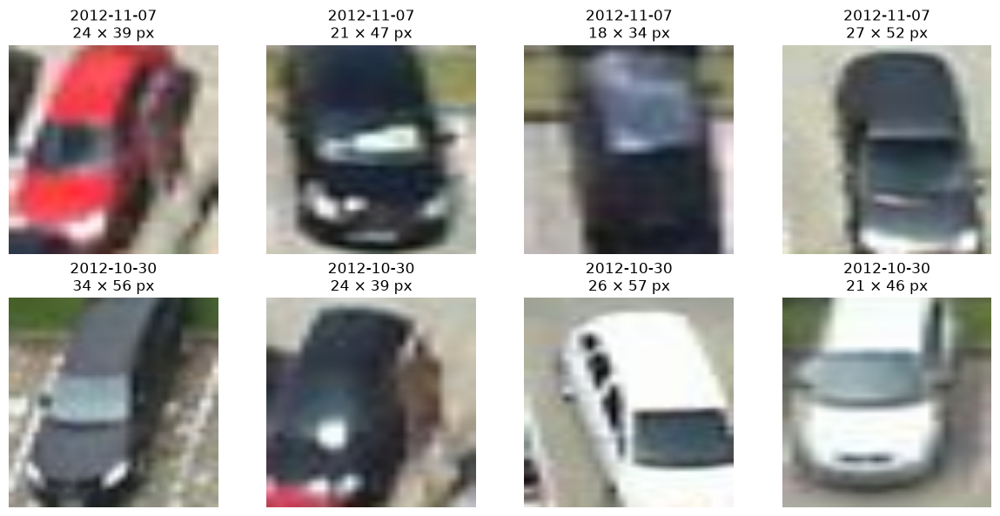

In [38]:
import matplotlib.pyplot as plt
from PIL import Image

schwierige_tage = ["2012-11-07", "2012-10-30"]
auswahl = analyse[analyse["datum"].isin(schwierige_tage)].copy()

print("Klassen an den beiden Tagen (0 = belegt, 1 = frei):")
print(pd.crosstab(auswahl["datum"], auswahl["wahr"]))

print("\nFehler nach Tag und Ausschnittgröße:")
print(pd.crosstab(
    [auswahl["datum"], auswahl["groesse"]],
    auswahl["ergebnis"]
).to_string())

fig, achsen = plt.subplots(2, 4, figsize=(12, 6))

for zeile, tag in enumerate(schwierige_tage):
    fehler = auswahl[
        (auswahl["datum"] == tag) &
        (auswahl["ergebnis"] == "frei → belegt")
    ].sample(n=4, random_state=42)

    for spalte, (_, eintrag) in enumerate(fehler.iterrows()):
        datei = (
            bildordner / "test" / "frei" /
            f"{eintrag['ausschnittname']}.png"
        )
        with Image.open(datei) as bild:
            achsen[zeile, spalte].imshow(
                bild.resize((160, 160), Image.Resampling.BILINEAR)
            )
        achsen[zeile, spalte].set_title(
            f"{tag}\n{eintrag['breite']:.0f} × "
            f"{eintrag['hoehe']:.0f} px"
        )
        achsen[zeile, spalte].axis("off")

plt.tight_layout()
plt.show()

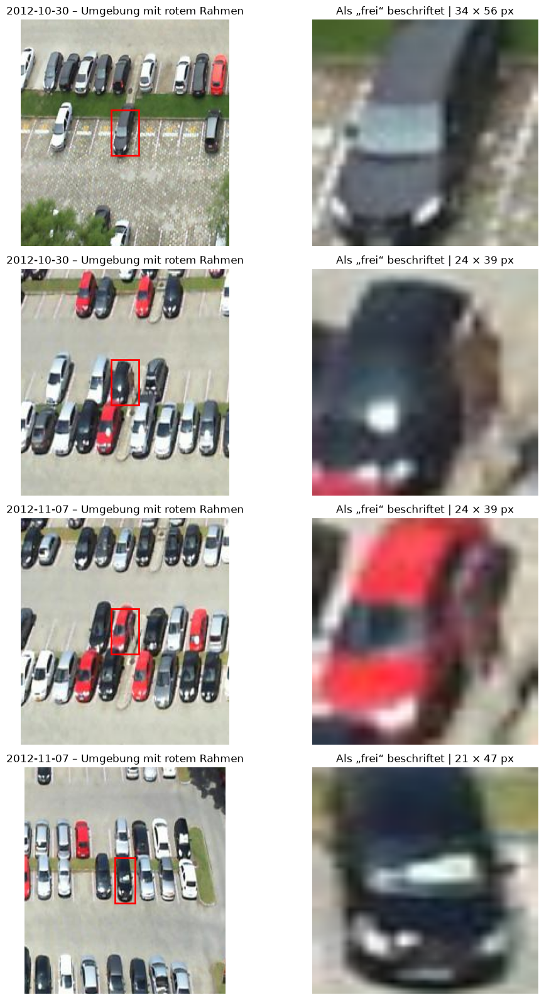

In [40]:
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import pandas as pd

projektordner = Path.cwd()
datenordner = Path(kagglehub.dataset_download("ammarnassanalhajali/pklot-dataset/versions/1"))
bildordner = Path.home() / ".cache/edgeai-parking/ausschnitte_v1"

analyse = pd.read_csv(projektordner / "testergebnisse.csv")
stichprobe = pd.read_csv(projektordner / "stichprobe.csv")
stichprobe["ausschnittname"] = (
    stichprobe["markierung_id"].astype(str)
    .str.replace(":", "_", regex=False)
)
stichprobe = stichprobe.set_index("ausschnittname")

beispiele = pd.concat([
    analyse[
        (analyse["datum"] == tag) &
        (analyse["wahr"] == 1) &
        (analyse["vorhergesagt"] == 0)
    ].sample(n=2, random_state=42)
    for tag in ["2012-10-30", "2012-11-07"]
])

fig, achsen = plt.subplots(4, 2, figsize=(11, 16))

for zeile, (_, beispiel) in enumerate(beispiele.iterrows()):
    info = stichprobe.loc[beispiel["ausschnittname"]]
    originalpfad = datenordner / info["original_split"] / info["bildname"]
    ausschnittpfad = (
        bildordner / "test" / "frei" /
        f"{beispiel['ausschnittname']}.png"
    )

    x, y = float(info["x"]), float(info["y"])
    breite, hoehe = float(info["breite"]), float(info["hoehe"])

    with Image.open(originalpfad) as original:
        achsen[zeile, 0].imshow(original)
        achsen[zeile, 0].add_patch(Rectangle(
            (x, y), breite, hoehe,
            fill=False, edgecolor="red", linewidth=2
        ))

        # Umgebung des Stellplatzes vergrößert anzeigen
        rand = max(65, 2 * max(breite, hoehe))
        achsen[zeile, 0].set_xlim(
            max(0, x - rand), min(original.width, x + breite + rand)
        )
        achsen[zeile, 0].set_ylim(
            min(original.height, y + hoehe + rand), max(0, y - rand)
        )

    with Image.open(ausschnittpfad) as ausschnitt:
        achsen[zeile, 1].imshow(
            ausschnitt.resize((160, 160), Image.Resampling.BILINEAR)
        )

    achsen[zeile, 0].set_title(
        f"{beispiel['datum']} – Umgebung mit rotem Rahmen"
    )
    achsen[zeile, 1].set_title(
        f"Als „frei“ beschriftet | {breite:.0f} × {hoehe:.0f} px"
    )
    achsen[zeile, 0].axis("off")
    achsen[zeile, 1].axis("off")

plt.tight_layout()
plt.show()

In [42]:
import json
from pathlib import Path
import pandas as pd

projektordner = Path.cwd()
datenordner = Path(kagglehub.dataset_download("ammarnassanalhajali/pklot-dataset/versions/1"))

analyse = pd.read_csv(projektordner / "testergebnisse.csv")
stichprobe = pd.read_csv(projektordner / "stichprobe.csv")
stichprobe["ausschnittname"] = (
    stichprobe["markierung_id"].astype(str)
    .str.replace(":", "_", regex=False)
)
stichprobe = stichprobe.set_index("ausschnittname")

beispiele = pd.concat([
    analyse[
        (analyse["datum"] == tag) &
        (analyse["wahr"] == 1) &
        (analyse["vorhergesagt"] == 0)
    ].sample(n=2, random_state=42)
    for tag in ["2012-10-30", "2012-11-07"]
])

coco_cache = {}
ergebniszeilen = []

for _, beispiel in beispiele.iterrows():
    info = stichprobe.loc[beispiel["ausschnittname"]]
    split = info["original_split"]

    if split not in coco_cache:
        datei = datenordner / split / "_annotations.coco.json"
        with open(datei, encoding="utf-8") as f:
            coco_cache[split] = json.load(f)

    coco = coco_cache[split]
    markierungs_id = str(info["markierung_id"]).split(":")[-1]
    original = next(
        (a for a in coco["annotations"]
         if str(a["id"]) == markierungs_id),
        None
    )
    if original is None:
        raise ValueError(f"Markierung nicht gefunden: {info['markierung_id']}")

    kategorien = {k["id"]: k["name"] for k in coco["categories"]}
    bild = next(
        b for b in coco["images"]
        if b["id"] == original["image_id"]
    )

    csv_box = [
        float(info["x"]), float(info["y"]),
        float(info["breite"]), float(info["hoehe"])
    ]

    ergebniszeilen.append({
        "datum": beispiel["datum"],
        "CSV-Klasse": info["klasse"],
        "COCO-Klasse": kategorien[original["category_id"]],
        "Bild stimmt": bild["file_name"] == info["bildname"],
        "Rahmen stimmt": all(
            abs(a - b) < 0.01
            for a, b in zip(csv_box, original["bbox"])
        ),
    })

print(pd.DataFrame(ergebniszeilen).to_string(index=False))

     datum CSV-Klasse COCO-Klasse  Bild stimmt  Rahmen stimmt
2012-10-30       frei space-empty         True           True
2012-10-30       frei space-empty         True           True
2012-11-07       frei space-empty         True           True
2012-11-07       frei space-empty         True           True


## ONNX-Export und Optimierungsversuche

FP32 wird exportiert. Die nachfolgenden Zellen dokumentieren vollständige und partielle INT8-Varianten, Validierung, Test und Laufzeitvergleich. Die Voll-INT8-Varianten erwiesen sich in diesem Versuch als unzuverlässig.


In [44]:
from pathlib import Path
import numpy as np
import onnx
import onnxruntime as ort
import torch
from torch import nn
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_small

projektordner = Path.cwd()
bildordner = Path.home() / ".cache/edgeai-parking/ausschnitte_v1"
modell_datei = projektordner / "mobilenetv3_bestes_modell.pt"
onnx_datei = projektordner / "mobilenetv3_fp32.onnx"

paket = torch.load(modell_datei, map_location="cpu", weights_only=True)
export_modell = mobilenet_v3_small(weights=None)
export_modell.classifier[-1] = nn.Linear(
    export_modell.classifier[-1].in_features, 2
)
export_modell.load_state_dict(paket["model_state_dict"])
export_modell.eval()

torch.onnx.export(
    export_modell,
    torch.randn(1, 3, 160, 160),
    str(onnx_datei),
    input_names=["bild"],
    output_names=["logits"],
    dynamic_axes={"bild": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=17,
    dynamo=False
)

onnx.checker.check_model(str(onnx_datei))

vorbereitung = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

validierung = datasets.ImageFolder(
    bildordner / "valid", transform=vorbereitung
)
indizes = np.linspace(0, len(validierung) - 1, 16, dtype=int)
bilder = torch.stack(
    [validierung[int(i)][0] for i in indizes]
)

with torch.inference_mode():
    pytorch_ausgabe = export_modell(bilder).numpy()

sitzung = ort.InferenceSession(
    str(onnx_datei), providers=["CPUExecutionProvider"]
)
onnx_ausgabe = sitzung.run(
    None, {"bild": bilder.numpy()}
)[0]

abweichung = np.max(np.abs(pytorch_ausgabe - onnx_ausgabe))
gleiche_klassen = np.count_nonzero(
    pytorch_ausgabe.argmax(axis=1) == onnx_ausgabe.argmax(axis=1)
)

print("ONNX-Datei:", onnx_datei)
print("Dateigröße: {:.2f} MiB".format(
    onnx_datei.stat().st_size / 1024**2
))
print("Größte Abweichung der Modellausgaben:", abweichung)
print(f"Gleiche Vorhersage: {gleiche_klassen}/16")

assert gleiche_klassen == 16
assert abweichung < 0.001

<TEMP>:23: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX-Datei: <PROJEKTORDNER>/mobilenetv3_fp32.onnx
Dateigröße: 5.81 MiB
Größte Abweichung der Modellausgaben: 2.3126602e-05
Gleiche Vorhersage: 16/16


In [1]:
from torchvision import transforms

vorbereitung = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

In [3]:
import time
from pathlib import Path

import numpy as np
import onnx
import onnxruntime as ort
import pandas as pd
from PIL import Image
from onnxruntime.quantization import (
    CalibrationDataReader, CalibrationMethod,
    QuantFormat, QuantType, quantize_static
)

projektordner = Path.cwd()
bildordner = Path.home() / ".cache/edgeai-parking/ausschnitte_v1"
fp32_datei = projektordner / "mobilenetv3_fp32.onnx"
int8_datei = projektordner / "mobilenetv3_int8.onnx"

stichprobe = pd.read_csv(projektordner / "stichprobe.csv")
train = stichprobe.loc[stichprobe["gruppe"] == "train"].copy()

# Erst jeden vorhandenen Tag und jede dort vorhandene Klasse abdecken
grundauswahl = train.groupby(
    ["datum", "klasse"], group_keys=False
).sample(n=1, random_state=42)

rest = train.drop(index=grundauswahl.index)
teile = [grundauswahl]

for klasse in ["frei", "belegt"]:
    fehlen = 256 - (grundauswahl["klasse"] == klasse).sum()
    teile.append(
        rest.loc[rest["klasse"] == klasse]
        .sample(n=fehlen, random_state=42)
    )

kalibrierung = (
    pd.concat(teile)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

assert len(kalibrierung) == 512
assert kalibrierung["datum"].nunique() == train["datum"].nunique()

class BildLeser(CalibrationDataReader):
    def __init__(self, zeilen, stapelgroesse=8):
        self.zeilen = zeilen
        self.stapelgroesse = stapelgroesse
        self.position = 0

    def get_next(self):
        if self.position >= len(self.zeilen):
            return None

        teil = self.zeilen.iloc[
            self.position:self.position + self.stapelgroesse
        ]
        self.position += len(teil)

        bilder = []
        for _, eintrag in teil.iterrows():
            name = str(eintrag["markierung_id"]).replace(":", "_") + ".png"
            datei = bildordner / "train" / eintrag["klasse"] / name

            with Image.open(datei) as bild:
                bilder.append(
                    vorbereitung(bild.convert("RGB")).numpy()
                )

        return {"bild": np.stack(bilder).astype(np.float32)}

print(
    "Kalibrierung:",
    len(kalibrierung), "Trainingsbilder aus",
    kalibrierung["datum"].nunique(), "Aufnahmetagen"
)
print(kalibrierung["klasse"].value_counts().to_dict())

start = time.perf_counter()

quantize_static(
    model_input=str(fp32_datei),
    model_output=str(int8_datei),
    calibration_data_reader=BildLeser(kalibrierung),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QInt8,
    weight_type=QuantType.QInt8,
    calibrate_method=CalibrationMethod.MinMax,
    per_channel=False
)

onnx.checker.check_model(str(int8_datei))
int8_sitzung = ort.InferenceSession(
    str(int8_datei), providers=["CPUExecutionProvider"]
)

print("INT8-Modell:", int8_datei)
print("Erstellungszeit: {:.1f} Sekunden".format(time.perf_counter() - start))
print("FP32-Größe: {:.2f} MiB".format(fp32_datei.stat().st_size / 1024**2))
print("INT8-Größe: {:.2f} MiB".format(int8_datei.stat().st_size / 1024**2))
print("CPU-Modell geladen:", int8_sitzung.get_providers())

Kalibrierung: 512 Trainingsbilder aus 69 Aufnahmetagen
{'frei': 256, 'belegt': 256}


INT8-Modell: <PROJEKTORDNER>/mobilenetv3_int8.onnx
Erstellungszeit: 1.0 Sekunden
FP32-Größe: 5.81 MiB
INT8-Größe: 1.64 MiB
CPU-Modell geladen: ['CPUExecutionProvider']


In [5]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import onnxruntime as ort
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

projektordner = Path.cwd()
bildordner = Path.home() / ".cache/edgeai-parking/ausschnitte_v1"

vorbereitung = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

validierung = datasets.ImageFolder(
    bildordner / "valid", transform=vorbereitung
)
loader = DataLoader(validierung, batch_size=32, shuffle=False, num_workers=0)

# Gleiche CPU-Einstellungen für beide Modelle
optionen = ort.SessionOptions()
optionen.intra_op_num_threads = 1
optionen.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
optionen.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

dateien = {
    "FP32": projektordner / "mobilenetv3_fp32.onnx",
    "INT8": projektordner / "mobilenetv3_int8.onnx",
}
sitzungen = {
    name: ort.InferenceSession(
        str(datei),
        sess_options=optionen,
        providers=["CPUExecutionProvider"]
    )
    for name, datei in dateien.items()
}

# Vorhersagen auf allen 2.000 Validierungsbildern
vorhersagen = {"FP32": [], "INT8": []}
wahr = []

for bilder, klassen in loader:
    eingabe = bilder.numpy()
    wahr.extend(klassen.numpy())

    for name, sitzung in sitzungen.items():
        logits = sitzung.run(None, {"bild": eingabe})[0]
        vorhersagen[name].extend(logits.argmax(axis=1))

wahr = np.asarray(wahr)
vorhersagen = {
    name: np.asarray(werte) for name, werte in vorhersagen.items()
}

# 150 bereits vorbereitete Einzelbilder für die Laufzeitmessung
rng = np.random.default_rng(42)
indizes = rng.choice(len(validierung), size=150, replace=False)
messbilder = [
    validierung[int(i)][0].unsqueeze(0).numpy()
    for i in indizes
]

for sitzung in sitzungen.values():
    for bild in messbilder[:20]:
        sitzung.run(None, {"bild": bild})  # Aufwärmen

zeiten = {"FP32": [], "INT8": []}

for durchgang in range(4):
    reihenfolge = (
        ["FP32", "INT8"] if durchgang % 2 == 0
        else ["INT8", "FP32"]
    )
    for name in reihenfolge:
        sitzung = sitzungen[name]
        for bild in messbilder:
            start = time.perf_counter_ns()
            sitzung.run(None, {"bild": bild})
            zeiten[name].append(
                (time.perf_counter_ns() - start) / 1_000_000
            )

zeilen = []
for name in ["FP32", "INT8"]:
    zeilen.append({
        "Modell": name,
        "Größe MiB": dateien[name].stat().st_size / 1024**2,
        "Validierung Accuracy": accuracy_score(wahr, vorhersagen[name]),
        "Validierung F1-macro": f1_score(
            wahr, vorhersagen[name], average="macro"
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            wahr, vorhersagen[name]
        ),
        "Latenz Median ms": np.median(zeiten[name]),
        "Latenz p95 ms": np.percentile(zeiten[name], 95),
    })

vergleich = pd.DataFrame(zeilen)
print(vergleich.round(4).to_string(index=False))
print(
    "\nUnterschiedliche Vorhersagen:",
    np.count_nonzero(vorhersagen["FP32"] != vorhersagen["INT8"]),
    "von", len(wahr)
)

vergleich.to_csv(
    projektordner / "vergleich_validierung.csv", index=False
)

Modell  Größe MiB  Validierung Accuracy  Validierung F1-macro  Balanced Accuracy  Latenz Median ms  Latenz p95 ms
  FP32     5.8072                0.9955                0.9955             0.9956            2.0475         2.1930
  INT8     1.6412                0.4875                0.3418             0.5082            0.6330         0.6748

Unterschiedliche Vorhersagen: 1020 von 2000


In [7]:
from sklearn.metrics import confusion_matrix
from onnxruntime.quantization import (
    CalibrationMethod, QuantFormat, QuantType, quantize_static
)
import onnx
import onnxruntime as ort
import numpy as np

print("Bisheriges INT8 – Zeilen tatsächlich, Spalten vorhergesagt:")
print("Klassen: ['belegt', 'frei']")
print(confusion_matrix(wahr, vorhersagen["INT8"]))

u8_datei = projektordner / "mobilenetv3_int8_u8u8.onnx"

quantize_static(
    model_input=str(projektordner / "mobilenetv3_fp32.onnx"),
    model_output=str(u8_datei),
    calibration_data_reader=BildLeser(kalibrierung),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QUInt8,
    weight_type=QuantType.QUInt8,
    calibrate_method=CalibrationMethod.MinMax,
    per_channel=False
)

onnx.checker.check_model(str(u8_datei))
u8_sitzung = ort.InferenceSession(
    str(u8_datei),
    sess_options=optionen,
    providers=["CPUExecutionProvider"]
)

u8_vorhersagen = []
for bilder, _ in loader:
    logits = u8_sitzung.run(None, {"bild": bilder.numpy()})[0]
    u8_vorhersagen.extend(logits.argmax(axis=1))

u8_vorhersagen = np.asarray(u8_vorhersagen)

print("\nNeues U8U8-Modell:")
print("Dateigröße: {:.2f} MiB".format(
    u8_datei.stat().st_size / 1024**2
))
print("Accuracy:", round(accuracy_score(wahr, u8_vorhersagen), 4))
print("F1-macro:", round(f1_score(wahr, u8_vorhersagen, average="macro"), 4))
print(
    "Andere Vorhersagen als FP32:",
    np.count_nonzero(u8_vorhersagen != vorhersagen["FP32"]),
    "von", len(wahr)
)
print("Konfusionsmatrix:")
print(confusion_matrix(wahr, u8_vorhersagen))

Bisheriges INT8 – Zeilen tatsächlich, Spalten vorhergesagt:
Klassen: ['belegt', 'frei']
[[  17 1025]
 [   0  958]]



Neues U8U8-Modell:
Dateigröße: 1.64 MiB
Accuracy: 0.486
F1-macro: 0.3387
Andere Vorhersagen als FP32: 1023 von 2000
Konfusionsmatrix:
[[  14 1028]
 [   0  958]]


In [9]:
from onnxruntime.quantization.shape_inference import quant_pre_process
from onnxruntime.quantization import (
    CalibrationMethod, QuantFormat, QuantType, quantize_static
)
from sklearn.metrics import accuracy_score, f1_score
import onnx
import onnxruntime as ort
import numpy as np

fp32_datei = projektordner / "mobilenetv3_fp32.onnx"
vorbereitet_datei = projektordner / "mobilenetv3_fp32_vorbereitet.onnx"

quant_pre_process(
    input_model=str(fp32_datei),
    output_model_path=str(vorbereitet_datei),
    skip_symbolic_shape=True
)

# Vor der Quantisierung prüfen, ob die Vorbereitung die Ausgaben erhält
vorbereitet_sitzung = ort.InferenceSession(
    str(vorbereitet_datei),
    sess_options=optionen,
    providers=["CPUExecutionProvider"]
)

pruefbilder = np.stack([
    validierung[i][0].numpy() for i in range(16)
])
original = sitzungen["FP32"].run(None, {"bild": pruefbilder})[0]
vorbereitet = vorbereitet_sitzung.run(
    None, {"bild": pruefbilder}
)[0]

abweichung = np.max(np.abs(original - vorbereitet))
print("FP32-Abweichung durch Vorbereitung:", abweichung)
assert abweichung < 0.001, "Die Vorbereitung hat das FP32-Modell verändert."

varianten = [
    ("int8_vorbereitet", {}),
    ("int8_nur_conv", {
        "op_types_to_quantize": ["Conv"],
        "per_channel": True
    }),
]

for name, zusatz in varianten:
    ausgabe_datei = projektordner / f"mobilenetv3_{name}.onnx"

    quantize_static(
        model_input=str(vorbereitet_datei),
        model_output=str(ausgabe_datei),
        calibration_data_reader=BildLeser(kalibrierung),
        quant_format=QuantFormat.QDQ,
        activation_type=QuantType.QInt8,
        weight_type=QuantType.QInt8,
        calibrate_method=CalibrationMethod.MinMax,
        **zusatz
    )

    onnx.checker.check_model(str(ausgabe_datei))
    sitzung = ort.InferenceSession(
        str(ausgabe_datei),
        sess_options=optionen,
        providers=["CPUExecutionProvider"]
    )

    prognosen = []
    for bilder, _ in loader:
        logits = sitzung.run(None, {"bild": bilder.numpy()})[0]
        prognosen.extend(logits.argmax(axis=1))

    prognosen = np.asarray(prognosen)

    print(f"\n{name}")
    print("Größe MiB:", round(ausgabe_datei.stat().st_size / 1024**2, 3))
    print("Accuracy:", round(accuracy_score(wahr, prognosen), 4))
    print("F1-macro:", round(f1_score(wahr, prognosen, average="macro"), 4))
    print("Als 'belegt' vorhergesagt:", int((prognosen == 0).sum()))
    print(
        "Abweichende Vorhersagen gegenüber FP32:",
        int((prognosen != vorhersagen["FP32"]).sum())
    )

FP32-Abweichung durch Vorbereitung: 0.0

int8_vorbereitet
Größe MiB: 1.641
Accuracy: 0.4875
F1-macro: 0.3418
Als 'belegt' vorhergesagt: 17
Abweichende Vorhersagen gegenüber FP32: 1020

int8_nur_conv
Größe MiB: 3.438
Accuracy: 0.499
F1-macro: 0.3689
Als 'belegt' vorhergesagt: 50
Abweichende Vorhersagen gegenüber FP32: 997


In [11]:
from collections import Counter
from onnxruntime.quantization import (
    CalibrationMethod, QuantFormat, QuantType, quantize_static
)
from sklearn.metrics import accuracy_score, f1_score
import onnx
import onnxruntime as ort
import numpy as np

operatoren = Counter(
    knoten.op_type
    for knoten in onnx.load(str(vorbereitet_datei)).graph.node
)
print("Gemm-Operatoren:", operatoren["Gemm"])
assert operatoren["Gemm"] > 0

gemm_datei = projektordner / "mobilenetv3_int8_nur_gemm.onnx"

quantize_static(
    model_input=str(vorbereitet_datei),
    model_output=str(gemm_datei),
    calibration_data_reader=BildLeser(kalibrierung),
    quant_format=QuantFormat.QDQ,
    op_types_to_quantize=["Gemm"],
    activation_type=QuantType.QInt8,
    weight_type=QuantType.QInt8,
    calibrate_method=CalibrationMethod.MinMax,
    per_channel=False
)

onnx.checker.check_model(str(gemm_datei))
gemm_sitzung = ort.InferenceSession(
    str(gemm_datei),
    sess_options=optionen,
    providers=["CPUExecutionProvider"]
)

gemm_prognosen = []
for bilder, _ in loader:
    logits = gemm_sitzung.run(None, {"bild": bilder.numpy()})[0]
    gemm_prognosen.extend(logits.argmax(axis=1))

gemm_prognosen = np.asarray(gemm_prognosen)

print("Größe MiB:", round(gemm_datei.stat().st_size / 1024**2, 3))
print("Accuracy:", round(accuracy_score(wahr, gemm_prognosen), 4))
print("F1-macro:", round(f1_score(wahr, gemm_prognosen, average="macro"), 4))
print(
    "Andere Vorhersagen als FP32:",
    int((gemm_prognosen != vorhersagen["FP32"]).sum()),
    "von", len(wahr)
)
print("Als 'belegt' vorhergesagt:", int((gemm_prognosen == 0).sum()))

Gemm-Operatoren: 2
Größe MiB: 4.128
Accuracy: 0.9955
F1-macro: 0.9955
Andere Vorhersagen als FP32: 0 von 2000
Als 'belegt' vorhergesagt: 1037


In [17]:
import time
import numpy as np
import pandas as pd

modelle = {
    "FP32": sitzungen["FP32"],
    "Teil-INT8 (Gemm)": gemm_sitzung,
}
modell_dateien = {
    "FP32": projektordner / "mobilenetv3_fp32.onnx",
    "Teil-INT8 (Gemm)": gemm_datei,
}

for sitzung in modelle.values():
    for bild in messbilder[:20]:
        sitzung.run(None, {"bild": bild})

messzeiten = {name: [] for name in modelle}

for durchgang in range(4):
    reihenfolge = (
        list(modelle) if durchgang % 2 == 0
        else list(reversed(modelle))
    )
    for name in reihenfolge:
        for bild in messbilder:
            start = time.perf_counter_ns()
            modelle[name].run(None, {"bild": bild})
            messzeiten[name].append(
                (time.perf_counter_ns() - start) / 1_000_000
            )

resultate = pd.DataFrame([
    {
        "Modell": name,
        "Größe MiB": modell_dateien[name].stat().st_size / 1024**2,
        "Median ms": np.median(messzeiten[name]),
        "p95 ms": np.percentile(messzeiten[name], 95),
    }
    for name in modelle
])

print(resultate.round(4).to_string(index=False))
resultate.to_csv(
    projektordner / "vergleich_fp32_teilint8.csv", index=False
)

          Modell  Größe MiB  Median ms  p95 ms
            FP32     5.8072     2.0931  2.2674
Teil-INT8 (Gemm)     4.1276     2.0596  2.2452


In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import onnxruntime as ort
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, recall_score, confusion_matrix
)

projektordner = Path.cwd()
bildordner = Path.home() / ".cache/edgeai-parking/ausschnitte_v1"

vorbereitung = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

testdaten = datasets.ImageFolder(
    bildordner / "test", transform=vorbereitung
)
assert len(testdaten) == 3000
assert testdaten.class_to_idx == {"belegt": 0, "frei": 1}

optionen = ort.SessionOptions()
optionen.intra_op_num_threads = 1
optionen.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
optionen.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

dateien = {
    "FP32": projektordner / "mobilenetv3_fp32.onnx",
    "Teil-INT8 (Gemm)": projektordner / "mobilenetv3_int8_nur_gemm.onnx",
}
modelle = {
    name: ort.InferenceSession(
        str(datei),
        sess_options=optionen,
        providers=["CPUExecutionProvider"]
    )
    for name, datei in dateien.items()
}

test_vorhersagen = {name: [] for name in modelle}
wahr_test = []

for bilder, klassen in DataLoader(
    testdaten, batch_size=32, shuffle=False, num_workers=0
):
    eingabe = bilder.numpy()
    wahr_test.extend(klassen.numpy())

    for name, sitzung in modelle.items():
        logits = sitzung.run(None, {"bild": eingabe})[0]
        test_vorhersagen[name].extend(logits.argmax(axis=1))

wahr_test = np.asarray(wahr_test)
test_vorhersagen = {
    name: np.asarray(werte)
    for name, werte in test_vorhersagen.items()
}

zeilen = []
for name, prognosen in test_vorhersagen.items():
    recall_belegt, recall_frei = recall_score(
        wahr_test, prognosen, labels=[0, 1],
        average=None, zero_division=0
    )
    zeilen.append({
        "Modell": name,
        "Test Accuracy": accuracy_score(wahr_test, prognosen),
        "Test F1-macro": f1_score(
            wahr_test, prognosen, average="macro"
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            wahr_test, prognosen
        ),
        "Recall belegt": recall_belegt,
        "Recall frei": recall_frei,
    })

testvergleich = pd.DataFrame(zeilen)
print("Testwerte gegen die vorhandenen COCO-Beschriftungen:")
print(testvergleich.round(4).to_string(index=False))

print(
    "\nUnterschiedliche Vorhersagen FP32 / Teil-INT8:",
    int(np.count_nonzero(
        test_vorhersagen["FP32"] !=
        test_vorhersagen["Teil-INT8 (Gemm)"]
    )),
    "von 3000"
)

for name, prognosen in test_vorhersagen.items():
    print(f"\nKonfusionsmatrix {name} – Klassen: ['belegt', 'frei']")
    print(confusion_matrix(wahr_test, prognosen, labels=[0, 1]))

testvergleich.to_csv(
    projektordner / "vergleich_testmodelle.csv", index=False
)

Testwerte gegen die vorhandenen COCO-Beschriftungen:
          Modell  Test Accuracy  Test F1-macro  Balanced Accuracy  Recall belegt  Recall frei
            FP32          0.907         0.9033             0.9266         0.9953        0.858
Teil-INT8 (Gemm)          0.907         0.9033             0.9266         0.9953        0.858

Unterschiedliche Vorhersagen FP32 / Teil-INT8: 0 von 3000

Konfusionsmatrix FP32 – Klassen: ['belegt', 'frei']
[[1066    5]
 [ 274 1655]]

Konfusionsmatrix Teil-INT8 (Gemm) – Klassen: ['belegt', 'frei']
[[1066    5]
 [ 274 1655]]


## Manuelle Prüfung und Demo

Eine kleine manuell bewertete Stichprobe kontrolliert auffällige Quelllabels. Die Demo verwendet COCO-Rahmen als vorgegebene Stellplatzpositionen; sie erkennt die Positionen nicht selbständig.


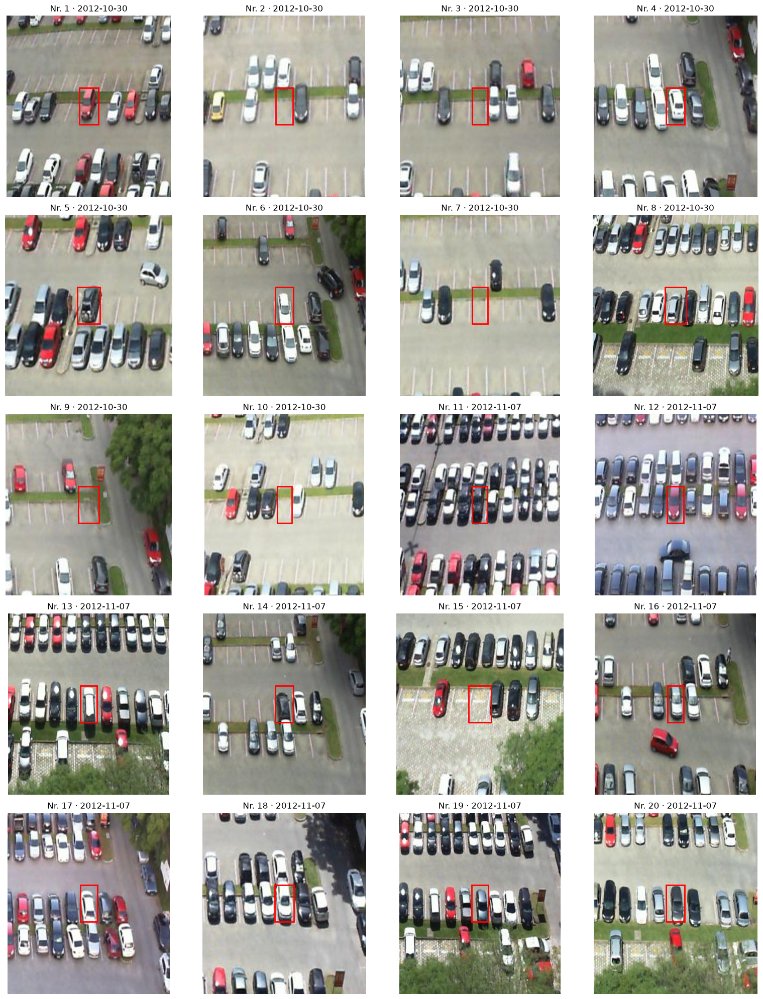

In [21]:
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import pandas as pd

projektordner = Path.cwd()
datenordner = Path(kagglehub.dataset_download("ammarnassanalhajali/pklot-dataset/versions/1"))

ergebnisse = pd.read_csv(projektordner / "testergebnisse.csv")
stichprobe = pd.read_csv(projektordner / "stichprobe.csv")
stichprobe["ausschnittname"] = (
    stichprobe["markierung_id"].astype(str)
    .str.replace(":", "_", regex=False)
)

tage = ["2012-10-30", "2012-11-07"]
audit = pd.concat([
    ergebnisse[
        (ergebnisse["datum"] == tag) &
        (ergebnisse["wahr"] == 1)
    ].sample(n=10, random_state=42)
    for tag in tage
], ignore_index=True)

audit = audit.merge(
    stichprobe[
        ["ausschnittname", "original_split", "bildname", "x", "y"]
    ],
    on="ausschnittname",
    how="left",
    validate="one_to_one"
)
assert audit["bildname"].notna().all()

audit.insert(0, "nummer", range(1, 21))
audit["manuelle_bewertung"] = ""
audit.to_csv(projektordner / "audit_stichprobe.csv", index=False)

fig, achsen = plt.subplots(5, 4, figsize=(16, 20))

for achse, (_, zeile) in zip(achsen.flat, audit.iterrows()):
    datei = datenordner / zeile["original_split"] / zeile["bildname"]
    x, y = float(zeile["x"]), float(zeile["y"])
    b, h = float(zeile["breite"]), float(zeile["hoehe"])

    with Image.open(datei) as bild:
        achse.imshow(bild)
        achse.add_patch(Rectangle(
            (x, y), b, h,
            fill=False, edgecolor="red", linewidth=2
        ))

        rand = max(70, 2 * max(b, h))
        achse.set_xlim(max(0, x-rand), min(bild.width, x+b+rand))
        achse.set_ylim(
            min(bild.height, y+h+rand), max(0, y-rand)
        )

    achse.set_title(f"Nr. {zeile['nummer']} · {zeile['datum']}")
    achse.axis("off")

plt.tight_layout()
plt.savefig(projektordner / "audit_stichprobe.png", dpi=150)
plt.show()

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

projektordner = Path.cwd()
audit_datei = projektordner / "audit_stichprobe.csv"
assert audit_datei.exists(), f"Datei nicht gefunden: {audit_datei}"

audit = pd.read_csv(audit_datei)
autos = {1, 4, 5, 6, 8, 11, 12, 13, 14, 16, 17, 18, 19, 20}
assert set(audit["nummer"]) == set(range(1, 21))

audit["manuelle_bewertung"] = np.where(
    audit["nummer"].isin(autos), "belegt", "frei"
)
audit["modellvorhersage"] = audit["vorhergesagt"].map(
    {0: "belegt", 1: "frei"}
)
audit["quelllabel_korrekt"] = (
    audit["manuelle_bewertung"] == "frei"
)
audit["modell_korrekt_manuell"] = (
    audit["modellvorhersage"] == audit["manuelle_bewertung"]
)

audit.to_csv(audit_datei, index=False)

print("Manuelle Bewertung nach Aufnahmetag:")
print(pd.crosstab(audit["datum"], audit["manuelle_bewertung"]))

print("\nModell gegen manuelle Bewertung:")
print(pd.crosstab(
    audit["manuelle_bewertung"], audit["modellvorhersage"]
))

print("\nFalsche Quelllabels:", int((~audit["quelllabel_korrekt"]).sum()), "/ 20")
print(
    "Modelltreffer in dieser Stichprobe:",
    int(audit["modell_korrekt_manuell"].sum()), "/ 20"
)
print("Gespeichert:", audit_datei)

Manuelle Bewertung nach Aufnahmetag:
manuelle_bewertung  belegt  frei
datum                           
2012-10-30               5     5
2012-11-07               9     1

Modell gegen manuelle Bewertung:
modellvorhersage    belegt  frei
manuelle_bewertung              
belegt                  14     0
frei                     0     6

Falsche Quelllabels: 14 / 20
Modelltreffer in dieser Stichprobe: 20 / 20
Gespeichert: <PROJEKTORDNER>/audit_stichprobe.csv


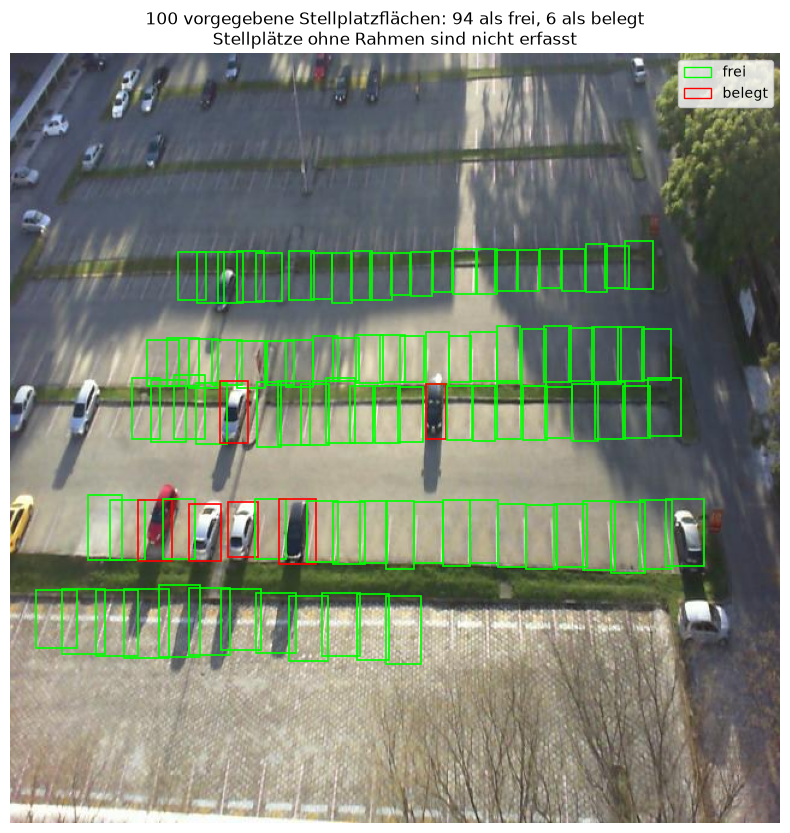

Aufnahmetag: 2012-09-28
Bewertete Stellplätze: 100
Als frei erkannt: 94
Als belegt erkannt: 6
Bild gespeichert: <PROJEKTORDNER>/parkplatz_demo.png


In [7]:
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
import numpy as np
import onnxruntime as ort
import pandas as pd
from PIL import Image
from torchvision import transforms

projektordner = Path.cwd()
datenordner = Path(kagglehub.dataset_download("ammarnassanalhajali/pklot-dataset/versions/1"))

# Einen Test-Aufnahmetag mit bislang unauffälligen Ergebnissen wählen
stichprobe = pd.read_csv(projektordner / "stichprobe.csv")
kandidaten = stichprobe[
    (stichprobe["gruppe"] == "test") &
    (stichprobe["datum"] == "2012-09-28")
]
assert len(kandidaten) > 0

split, bildname = (
    kandidaten.groupby(["original_split", "bildname"])
    .size().idxmax()
)

with open(datenordner / split / "_annotations.coco.json",
          encoding="utf-8") as f:
    coco = json.load(f)

bildeintrag = next(
    b for b in coco["images"] if b["file_name"] == bildname
)
rahmen = [
    a["bbox"] for a in coco["annotations"]
    if a["image_id"] == bildeintrag["id"]
    and a["category_id"] in (1, 2)
]
assert len(rahmen) > 0

vorbereitung = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

with Image.open(datenordner / split / bildname) as quelle:
    original = quelle.convert("RGB")
    ausschnitte = []

    for x, y, breite, hoehe in rahmen:
        ausschnitt = original.crop((
            math.floor(x), math.floor(y),
            math.ceil(x + breite), math.ceil(y + hoehe)
        ))
        ausschnitte.append(vorbereitung(ausschnitt).numpy())

optionen = ort.SessionOptions()
optionen.intra_op_num_threads = 1

sitzung = ort.InferenceSession(
    str(projektordner / "mobilenetv3_int8_nur_gemm.onnx"),
    sess_options=optionen,
    providers=["CPUExecutionProvider"]
)

logits = sitzung.run(
    None, {"bild": np.stack(ausschnitte).astype(np.float32)}
)[0]
klassen = logits.argmax(axis=1)  # 0 = belegt, 1 = frei

fig, achse = plt.subplots(figsize=(10, 10))
achse.imshow(original)

for (x, y, breite, hoehe), klasse in zip(rahmen, klassen):
    farbe = "red" if klasse == 0 else "lime"
    achse.add_patch(Rectangle(
        (x, y), breite, hoehe,
        fill=False, edgecolor=farbe, linewidth=1.2
    ))

achse.legend(handles=[
    Patch(facecolor="none", edgecolor="lime", label="frei"),
    Patch(facecolor="none", edgecolor="red", label="belegt")
])
achse.set_title(
    "100 vorgegebene Stellplatzflächen: 94 als frei, 6 als belegt\n"
    "Stellplätze ohne Rahmen sind nicht erfasst"
)
achse.axis("off")

demo_datei = projektordner / "parkplatz_demo.png"
plt.savefig(demo_datei, dpi=160, bbox_inches="tight")
plt.show()

print("Aufnahmetag: 2012-09-28")
print("Bewertete Stellplätze:", len(rahmen))
print("Als frei erkannt:", int((klassen == 1).sum()))
print("Als belegt erkannt:", int((klassen == 0).sum()))
print("Bild gespeichert:", demo_datei)

Rahmen am markierten Punkt: 1
Rahmen 87: COCO=belegt, Modell=frei, Modellausgabe für 'frei'=0.513, Größe=31.0 × 56.0 px


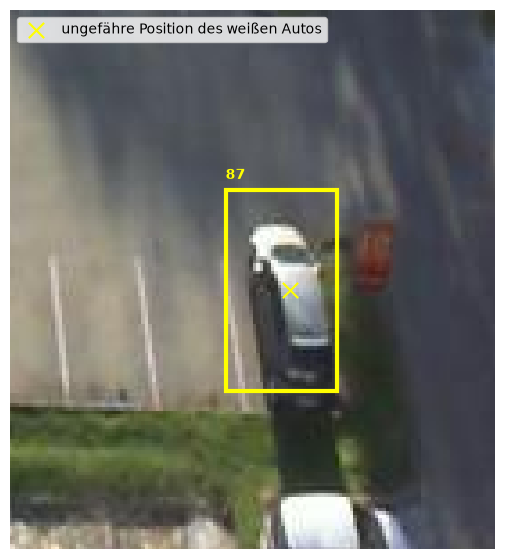

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Ungefähre Bildkoordinate des weißen Autos aus der Demo
ziel_x, ziel_y = 563, 398

passende_annotationen = [
    a for a in coco["annotations"]
    if a["image_id"] == bildeintrag["id"]
    and a["category_id"] in (1, 2)
]
assert len(passende_annotationen) == len(rahmen)

treffer = [
    i for i, (x, y, b, h) in enumerate(rahmen)
    if x <= ziel_x <= x + b and y <= ziel_y <= y + h
]

print("Rahmen am markierten Punkt:", len(treffer))

fig, achse = plt.subplots(figsize=(8, 7))
achse.imshow(original)
achse.scatter(
    [ziel_x], [ziel_y], c="yellow", marker="x", s=120,
    label="ungefähre Position des weißen Autos"
)

for i in treffer:
    x, y, b, h = rahmen[i]
    werte = logits[i] - logits[i].max()
    wahrscheinlichkeiten = np.exp(werte)
    wahrscheinlichkeiten /= wahrscheinlichkeiten.sum()

    coco_klasse = {
        1: "frei", 2: "belegt"
    }[passende_annotationen[i]["category_id"]]
    modell_klasse = "belegt" if klassen[i] == 0 else "frei"

    print(
        f"Rahmen {i}: COCO={coco_klasse}, "
        f"Modell={modell_klasse}, "
        f"Modellausgabe für 'frei'={wahrscheinlichkeiten[1]:.3f}, "
        f"Größe={b:.1f} × {h:.1f} px"
    )

    achse.add_patch(Rectangle(
        (x, y), b, h, fill=False,
        edgecolor="yellow", linewidth=3
    ))
    achse.text(x, y - 3, str(i), color="yellow", weight="bold")

achse.set_xlim(485, 620)
achse.set_ylim(470, 320)
achse.legend(loc="upper left")
achse.axis("off")
plt.show()

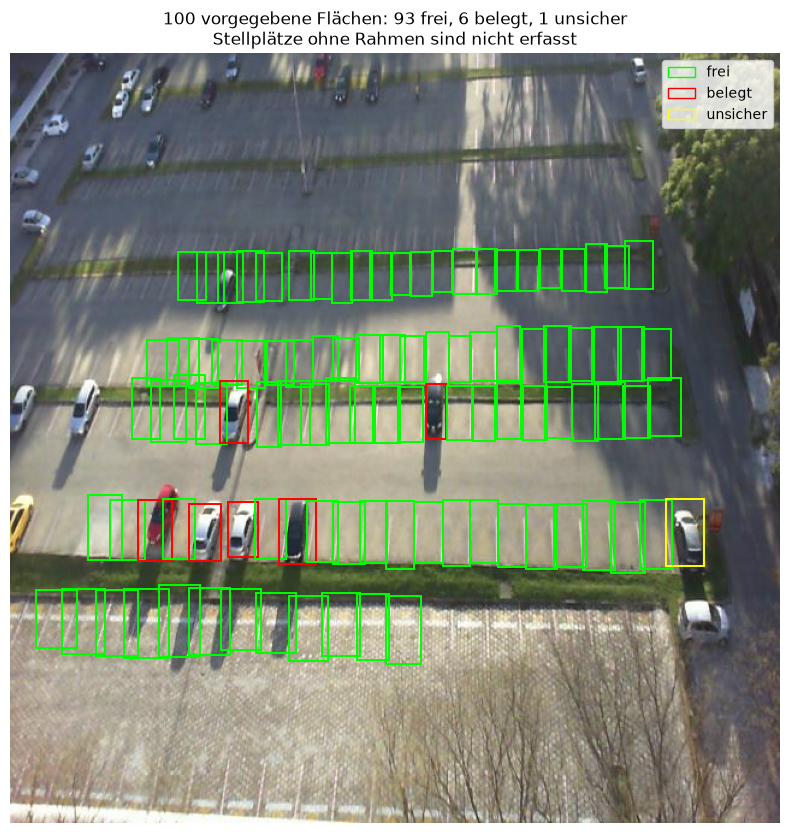

Rahmen 87: unsicher | Ausgabewert 'frei': 0.513
Gespeichert: <PROJEKTORDNER>/parkplatz_demo_mit_unsicherheit.png


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

werte = logits - logits.max(axis=1, keepdims=True)
exp_werte = np.exp(werte)
score_frei = exp_werte[:, 1] / exp_werte.sum(axis=1)

anzeige = np.full(len(rahmen), "unsicher", dtype=object)
anzeige[score_frei <= 0.20] = "belegt"
anzeige[score_frei >= 0.80] = "frei"

farben = {"frei": "lime", "belegt": "red", "unsicher": "yellow"}

fig, achse = plt.subplots(figsize=(10, 10))
achse.imshow(original)

for (x, y, breite, hoehe), status in zip(rahmen, anzeige):
    achse.add_patch(Rectangle(
        (x, y), breite, hoehe,
        fill=False, edgecolor=farben[status], linewidth=1.4
    ))

achse.legend(handles=[
    Patch(facecolor="none", edgecolor="lime", label="frei"),
    Patch(facecolor="none", edgecolor="red", label="belegt"),
    Patch(facecolor="none", edgecolor="yellow", label="unsicher")
])

achse.set_title(
    f"{len(rahmen)} vorgegebene Flächen: "
    f"{sum(anzeige == 'frei')} frei, "
    f"{sum(anzeige == 'belegt')} belegt, "
    f"{sum(anzeige == 'unsicher')} unsicher\n"
    "Stellplätze ohne Rahmen sind nicht erfasst"
)
achse.axis("off")

datei = projektordner / "parkplatz_demo_mit_unsicherheit.png"
plt.savefig(datei, dpi=160, bbox_inches="tight")
plt.show()

print("Rahmen 87:", anzeige[87],
      "| Ausgabewert 'frei':", round(float(score_frei[87]), 3))
print("Gespeichert:", datei)

In [13]:
from pathlib import Path
import numpy as np
import onnxruntime as ort
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

projektordner = Path.cwd()
bildordner = Path.home() / ".cache/edgeai-parking/ausschnitte_v1"

vorbereitung = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

validierung = datasets.ImageFolder(
    bildordner / "valid", transform=vorbereitung
)
assert validierung.class_to_idx == {"belegt": 0, "frei": 1}

optionen = ort.SessionOptions()
optionen.intra_op_num_threads = 1
sitzung = ort.InferenceSession(
    str(projektordner / "mobilenetv3_int8_nur_gemm.onnx"),
    sess_options=optionen,
    providers=["CPUExecutionProvider"]
)

alle_logits, wahr = [], []
for bilder, klassen in DataLoader(
    validierung, batch_size=32, shuffle=False, num_workers=0
):
    alle_logits.append(
        sitzung.run(None, {"bild": bilder.numpy()})[0]
    )
    wahr.extend(klassen.tolist())

alle_logits = np.concatenate(alle_logits)
wahr = np.asarray(wahr)

werte = alle_logits - alle_logits.max(axis=1, keepdims=True)
exp_werte = np.exp(werte)
score_frei = exp_werte[:, 1] / exp_werte.sum(axis=1)

# -1 = unsicher, 0 = belegt, 1 = frei
entscheidung = np.full(len(wahr), -1)
entscheidung[score_frei <= 0.20] = 0
entscheidung[score_frei >= 0.80] = 1
automatisch = entscheidung != -1

print("Validierungsbilder:", len(wahr))
print("Automatisch entschieden:", int(automatisch.sum()))
print("Unsicher:", int((~automatisch).sum()))
print(
    "Trefferquote der automatisch entschiedenen Bilder:",
    round(float((entscheidung[automatisch] == wahr[automatisch]).mean()), 4)
)
print(
    "Belegt fälschlich als frei ausgegeben:",
    int(((wahr == 0) & (entscheidung == 1)).sum())
)
print(
    "Frei fälschlich als belegt ausgegeben:",
    int(((wahr == 1) & (entscheidung == 0)).sum())
)

if "anzeige" in globals():
    print("\nVorführbild:")
    for status in ["frei", "belegt", "unsicher"]:
        print(status + ":", int((anzeige == status).sum()))

Validierungsbilder: 2000
Automatisch entschieden: 1951
Unsicher: 49
Trefferquote der automatisch entschiedenen Bilder: 0.9995
Belegt fälschlich als frei ausgegeben: 0
Frei fälschlich als belegt ausgegeben: 1

Vorführbild:
frei: 93
belegt: 6
unsicher: 1


In [15]:
import math
import time
import numpy as np
import pandas as pd

def verarbeite_kamerabild():
    start = time.perf_counter_ns()

    bilder = []
    for x, y, breite, hoehe in rahmen:
        ausschnitt = original.crop((
            math.floor(x), math.floor(y),
            math.ceil(x + breite), math.ceil(y + hoehe)
        ))
        bilder.append(vorbereitung(ausschnitt).numpy())

    eingabe = np.stack(bilder).astype(np.float32)
    nach_vorbereitung = time.perf_counter_ns()

    sitzung.run(None, {"bild": eingabe})
    ende = time.perf_counter_ns()

    return (
        (nach_vorbereitung - start) / 1_000_000,
        (ende - nach_vorbereitung) / 1_000_000,
        (ende - start) / 1_000_000,
    )

for _ in range(5):
    verarbeite_kamerabild()  # Aufwärmen

messungen = np.array([
    verarbeite_kamerabild() for _ in range(30)
])

namen = ["Bildvorbereitung", "Modellinferenz", "Gesamt"]
for spalte, name in enumerate(namen):
    print(
        f"{name}: Median {np.median(messungen[:, spalte]):.1f} ms, "
        f"p95 {np.percentile(messungen[:, spalte], 95):.1f} ms"
    )

print("Stellplätze pro Bild:", len(rahmen))
print(
    "Bilder pro Sekunde (aus Gesamtmedian):",
    round(1000 / np.median(messungen[:, 2]), 2)
)

pd.DataFrame(messungen, columns=[
    "vorbereitung_ms", "inferenz_ms", "gesamt_ms"
]).to_csv(
    projektordner / "benchmark_vollbild.csv", index=False
)

Bildvorbereitung: Median 41.8 ms, p95 43.2 ms
Modellinferenz: Median 218.0 ms, p95 222.8 ms
Gesamt: Median 259.7 ms, p95 265.1 ms
Stellplätze pro Bild: 100
Bilder pro Sekunde (aus Gesamtmedian): 3.85


## Speicher- und Energiemessung

Der Speichervergleich startet getrennte Python-Prozesse. Die Energie-Skripte verwenden macOS `powermetrics` und benötigen eine lokale sudo-Freigabe; genaue Hinweise stehen in README.md.


In [2]:
import json
import subprocess
import sys
from pathlib import Path
import pandas as pd

projektordner = Path.cwd()

messprogramm = r"""
import json
import resource
import sys
import numpy as np
import onnxruntime as ort

def spitzenwert_mib():
    # Auf macOS liefert ru_maxrss Bytes.
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

vorher = spitzenwert_mib()

optionen = ort.SessionOptions()
optionen.intra_op_num_threads = 1
sitzung = ort.InferenceSession(
    sys.argv[1],
    sess_options=optionen,
    providers=["CPUExecutionProvider"]
)
nach_laden = spitzenwert_mib()

eingabe = np.empty((100, 3, 160, 160), dtype=np.float32)
eingabe.fill(0.5)
sitzung.run(None, {"bild": eingabe})
nach_inferenz = spitzenwert_mib()

print(json.dumps({
    "vorher_mib": vorher,
    "nach_laden_mib": nach_laden,
    "spitzenwert_mib": nach_inferenz
}))
"""

ergebnisse = []
for name, dateiname in [
    ("FP32", "mobilenetv3_fp32.onnx"),
    ("Teil-INT8 (Gemm)", "mobilenetv3_int8_nur_gemm.onnx"),
]:
    datei = projektordner / dateiname
    assert datei.exists(), f"Datei fehlt: {datei}"

    lauf = subprocess.run(
        [sys.executable, "-c", messprogramm, str(datei)],
        capture_output=True, text=True, check=True
    )
    werte = json.loads(lauf.stdout.strip().splitlines()[-1])
    ergebnisse.append({"Modell": name, **werte})

tabelle = pd.DataFrame(ergebnisse)
print(tabelle.round(1).to_string(index=False))
tabelle.to_csv(projektordner / "messung_arbeitsspeicher.csv", index=False)

          Modell  vorher_mib  nach_laden_mib  spitzenwert_mib
            FP32        45.3            64.8            258.7
Teil-INT8 (Gemm)        44.4            65.8            258.6


## Entstehung des Energieskripts

Diese historische Notebook-Zelle schreibt `energievergleich.py` neu. Für die Prüfung liegen sowohl das normale als auch das umgekehrte Messskript bereits als eigene Dateien im Repository.


In [4]:
from pathlib import Path

skript = r'''
import re
import statistics
import subprocess
import sys
import tempfile
import time
from pathlib import Path

import numpy as np
import onnxruntime as ort

if sys.platform != "darwin":
    raise RuntimeError("Dieses Messskript ist für macOS gedacht.")

projektordner = Path(__file__).resolve().parent
eingabe = np.full((100, 3, 160, 160), 0.5, dtype=np.float32)

optionen = ort.SessionOptions()
optionen.intra_op_num_threads = 1

modelle = {
    "fp32": ort.InferenceSession(
        str(projektordner / "mobilenetv3_fp32.onnx"),
        sess_options=optionen,
        providers=["CPUExecutionProvider"],
    ),
    "teil_int8": ort.InferenceSession(
        str(projektordner / "mobilenetv3_int8_nur_gemm.onnx"),
        sess_options=optionen,
        providers=["CPUExecutionProvider"],
    ),
}

for sitzung in modelle.values():
    for _ in range(4):
        sitzung.run(None, {"bild": eingabe})

time.sleep(5)

def messen(name, sitzung=None):
    with tempfile.TemporaryFile(mode="w+t", encoding="utf-8") as protokoll:
        prozess = subprocess.Popen(
            [
                "sudo", "-n", "powermetrics",
                "--samplers", "cpu_power",
                "-i", "1000", "-n", "20",
            ],
            stdout=protokoll,
            stderr=subprocess.PIPE,
            text=True,
        )

        start = time.perf_counter()
        ende = start + 20.5
        stapel = 0

        if sitzung is None:
            time.sleep(max(0, ende - time.perf_counter()))
        else:
            while time.perf_counter() < ende:
                sitzung.run(None, {"bild": eingabe})
                stapel += 1

        dauer = time.perf_counter() - start
        _, fehler = prozess.communicate(timeout=15)
        protokoll.seek(0)
        rohtext = protokoll.read()

    if prozess.returncode != 0:
        raise RuntimeError(f"powermetrics bei {name}: {fehler}")

    (projektordner / f"energie_{name}.txt").write_text(
        rohtext, encoding="utf-8"
    )

    werte = [
        int(wert) for wert in re.findall(
            r"Combined Power \(CPU \+ GPU \+ ANE\):\s*(\d+)\s*mW",
            rohtext,
        )
    ]
    if len(werte) < 15:
        raise RuntimeError(
            f"Bei {name} wurden nur {len(werte)} Leistungswerte gefunden."
        )

    # Übergänge am Anfang und Ende nicht in den Mittelwert aufnehmen
    stabile_werte = werte[1:-1]
    mittel = statistics.mean(stabile_werte)

    print(
        f"{name}: {len(stabile_werte)} Werte, "
        f"Mittel {mittel:.0f} mW, "
        f"{stapel} Stapel à 100 Ausschnitte, "
        f"Dauer {dauer:.1f} s",
        flush=True,
    )

messen("leerlauf_vor")
messen("fp32", modelle["fp32"])
messen("teil_int8", modelle["teil_int8"])
messen("leerlauf_nach")
'''

datei = Path.cwd() / "energievergleich.py"
datei.write_text(skript, encoding="utf-8")
print("Messskript erstellt:", datei)

Messskript erstellt: <PROJEKTORDNER>/energievergleich.py
